<a href="https://colab.research.google.com/github/Nayemuzzaman007/Wifi-2.4-GHz-channel-with-RIS-panel-/blob/main/MIMO_RIS_channel_june_22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Global Setup
Run this cell to set up the environment, define functions, and initialize the scene variables in the global scope.

Array geometry check

In [ ]:
# @title Global Setup and Scene Configuration (Specific RIS Placement)
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"
import subprocess, sys

try:
    import numpy
    if numpy.__version__ != "1.26.4":
        raise ImportError
except ImportError:
    print("Installing NumPy 1.26.4 ...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "numpy==1.26.4", "--force-reinstall", "-q"])
    import os; os._exit(0)

def _ensure(pkg, name=None):
    try: __import__(name or pkg)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "install", pkg, "-q"])

_ensure("sionna")
_ensure("hdf5storage")

import gc, time, shutil
from pathlib import Path
import numpy as np
import tensorflow as tf
import hdf5storage
import mitsuba as mi
import drjit as dr
from sionna.rt import (load_scene, Transmitter, Receiver, PlanarArray, PathSolver, subcarrier_frequencies, AntennaArray)

try:
    from sionna.rt import Antenna
except ImportError:
    try:
        from sionna.rt.antenna import Antenna
    except ImportError:
        Antenna = None

for _gpu in tf.config.list_physical_devices("GPU"):
    try: tf.config.experimental.set_memory_growth(_gpu, True)
    except: pass

QUICK_TEST = False
PLANE_HALF, ROOM_LZ, TARGET_ROOMS, SCENE_SEED = 20.0, 5.0, 6, 88
WALL_HEIGHT_FRAC, N_RIS_PANELS = 0.90, 1     # Updated to 1 panel
RIS_NUM_ROWS, RIS_NUM_COLS = 20, 20
RIS_N = RIS_NUM_ROWS * RIS_NUM_COLS
RIS_MOUNT_HEIGHT, RIS_WALL_OFFSET = 2.5, 0.15
N_AP, AP_HEIGHT = 6, 2.5
FREQ_HZ = 2.4e9
NUM_SUBCARRIERS, NUM_SELECTED = 64, 8
SUBCARRIER_SPACING = 312500.0
_ALL_FREQS = np.array(subcarrier_frequencies(NUM_SUBCARRIERS, SUBCARRIER_SPACING))
F_STEP = NUM_SUBCARRIERS // NUM_SELECTED
F_OFF = F_STEP // 2
F_SEL_IDX = list(range(F_OFF, NUM_SUBCARRIERS, F_STEP))[:NUM_SELECTED]
FREQUENCIES = _ALL_FREQS[F_SEL_IDX]
F_SEL = len(FREQUENCIES)
MAX_DEPTH = 3 if QUICK_TEST else 4

PATH_CFG = dict(max_depth=MAX_DEPTH, los=True, specular_reflection=True, diffraction=True, synthetic_array=True)

TX_HEIGHT, TX_GRID_STEP, TX_WALL_MARGIN = 1.0, 1.0 if QUICK_TEST else 0.1, 0.5
OUT_DIR = Path("multiroom_2ghz_6ap_2ris")

# User-Requested RIS Positions
ris_panels = [
    {"cx": 0.5, "cy": 0.5, "cz": 2.5, "normal": [-1.0, -1.0, 0.0]}
]

def generate_floorplan(seed):
    rng = np.random.default_rng(seed)
    rooms = [{"x0":-PLANE_HALF,"x1":PLANE_HALF, "y0":-PLANE_HALF,"y1":PLANE_HALF}]
    walls, min_d = [], 5.0
    while len(rooms) < TARGET_ROOMS:
        rooms.sort(key=lambda r:(r["x1"]-r["x0"])*(r["y1"]-r["y0"]), reverse=True)
        room = rooms.pop(0)
        w, h = room["x1"]-room["x0"], room["y1"]-room["y0"]
        if w < min_d*2 and h < min_d*2: rooms.append(room); break
        if w >= h:
            sv = rng.uniform(room["x0"]+min_d, float(room["x1"])-min_d)
            rooms += [{"x0":room["x0"],"x1":sv, "y0":room["y0"],"y1":room["y1"], "id": len(rooms)}, {"x0":sv,"x1":room["x1"], "y0":room["y0"],"y1":room["y1"], "id": len(rooms)+1}]
            walls.append({"cx":sv, "cy":(room["y0"]+room["y1"])/2, "sx":0.05, "sy":(room["y1"]-room["y0"])/2, "orient": "V"})
        else:
            sv = rng.uniform(room["y0"]+min_d, float(room["y1"])-min_d)
            rooms += [{"x0":room["x0"],"x1":room["x1"], "y0":room["y0"],"y1":sv, "id": len(rooms)}, {"x0":room["x0"],"x1":room["x1"], "y0":sv,"y1":room["y1"], "id": len(rooms)+1}]
            walls.append({"cx":(room["x0"]+room["x1"])/2, "cy":sv, "sx":(room["x1"]-room["x0"])/2, "sy":0.05, "orient": "H"})
    furniture = []
    for room in rooms:
        area = (room["x1"]-room["x0"]) * (room["y1"]-room["y0"])
        n_items = int(rng.integers(1, 4)) if area > 100 else int(rng.integers(1, 3))
        for _ in range(n_items):
            fsx, fsy = float(rng.uniform(0.5, 1.0)), float(rng.uniform(0.5, 1.0))
            try: fcx, fcy = float(rng.uniform(room["x0"]+fsx+0.3, room["x1"]-fsx-0.3)), float(rng.uniform(room["y0"]+fsy+0.3, room["y1"]-fsy-0.3))
            except: continue
            fcz = float(rng.uniform(0.4, 0.9))
            furniture.append({"cx":fcx,"cy":fcy,"cz":fcz, "sx":fsx,"sy":fsy,"sz":fcz})
    return rooms, walls, furniture

def write_scene_xml(xml_path, walls, furniture):
    PH, hz, wall_hz = PLANE_HALF, ROOM_LZ/2.0, (ROOM_LZ*WALL_HEIGHT_FRAC)/2.0
    door_w = 0.6
    lines = ['<scene version="3.0.0">', '<bsdf type="itu-radio-material" id="m_concrete"><string name="type" value="concrete"/></bsdf>', '<bsdf type="itu-radio-material" id="m_plaster"><string name="type" value="plasterboard"/></bsdf>', f'<shape type="cube"><transform name="to_world"><scale x="{PH}" y="{PH}" z="0.05"/><translate x="0" y="0" z="-0.05"/></transform><ref id="m_concrete"/></shape>', f'<shape type="cube"><transform name="to_world"><scale x="{PH}" y="{PH}" z="0.05"/><translate x="0" y="0" z="{ROOM_LZ+0.05}"/></transform><ref id="m_concrete"/></shape>', f'<shape type="cube"><transform name="to_world"><scale x="0.05" y="{PH}" z="{hz}"/><translate x="{-PH-0.05}" y="0" z="{hz}"/></transform><ref id="m_concrete"/></shape>', f'<shape type="cube"><transform name="to_world"><scale x="0.05" y="{PH}" z="{hz}"/><translate x="{PH+0.05}" y="0" z="{hz}"/></transform><ref id="m_concrete"/></shape>', f'<shape type="cube"><transform name="to_world"><scale x="{PH}" y="0.05" z="{hz}"/><translate x="0" y="{-PH-0.05}" z="{hz}"/></transform><ref id="m_concrete"/></shape>', f'<shape type="cube"><transform name="to_world"><scale x="{PH}" y="0.05" z="{hz}"/><translate x="0" y="{PH+0.05}" z="{hz}"/></transform><ref id="m_concrete"/></shape>']
    for w in walls:
        if w["orient"] == "V":
            part_sy = (w["sy"]-door_w)/2.0
            lines.append(f'<shape type="cube"><transform name="to_world"><scale x="{w["sx"]}" y="{part_sy}" z="{wall_hz}"/><translate x="{w["cx"]}" y="{w["cy"]-part_sy-door_w}" z="{wall_hz}"/></transform><ref id="m_plaster"/></shape>')
            lines.append(f'<shape type="cube"><transform name="to_world"><scale x="{w["sx"]}" y="{part_sy}" z="{wall_hz}"/><translate x="{w["cx"]}" y="{w["cy"]+part_sy+door_w}" z="{wall_hz}"/></transform><ref id="m_plaster"/></shape>')
        else:
            part_sx = (w["sx"]-door_w)/2.0
            lines.append(f'<shape type="cube"><transform name="to_world"><scale x="{part_sx}" y="{w["sy"]}" z="{wall_hz}"/><translate x="{w["cx"]-part_sx-door_w}" y="{w["cy"]}" z="{wall_hz}"/></transform><ref id="m_plaster"/></shape>')
            lines.append(f'<shape type="cube"><transform name="to_world"><scale x="{w["sx"]-part_sx-door_w}" y="{w["sy"]}" z="{wall_hz}"/><translate x="{w["cx"]+part_sx+door_w}" y="{w["cy"]}" z="{wall_hz}"/></transform><ref id="m_plaster"/></shape>')
    for f in furniture: lines.append(f'<shape type="cube"><transform name="to_world"><scale x="{f["sx"]}" y="{f["sy"]}" z="{f["sz"]}"/><translate x="{f["cx"]}" y="{f["cy"]}" z="{f["cz"]}"/></transform><ref id="m_concrete"/></shape>')
    lines.append("</scene>")
    xml_path.write_text("\n".join(lines))

def make_user_array(): return PlanarArray(num_rows=1, num_cols=1, vertical_spacing=0.5, horizontal_spacing=0.5, pattern="dipole", polarization="V")
def make_ap_array():
    spacing = 0.5
    radius = spacing / (2 * np.sin(np.pi / N_AP))
    angles = np.linspace(0, 2*np.pi, N_AP, endpoint=False)
    positions = np.stack([radius * np.cos(angles), radius * np.sin(angles), np.zeros(N_AP)], axis=0).astype(np.float32)
    if Antenna is not None:
        ant = Antenna(pattern="dipole", polarization="V")
    else:
        ant = PlanarArray(num_rows=1, num_cols=1, vertical_spacing=0.5, horizontal_spacing=0.5, pattern="dipole", polarization="V").antenna_pattern
    return AntennaArray(ant, positions)
def make_ris_array(): return PlanarArray(num_rows=RIS_NUM_ROWS, num_cols=RIS_NUM_COLS, vertical_spacing=0.5, horizontal_spacing=0.5, pattern="iso", polarization="V")
def _cfr(paths): return np.asarray(paths.cfr(frequencies=FREQUENCIES, normalize=False, normalize_delays=False, out_type="numpy"))
def flat_to_grid(flat, valid_2d, tail):
    ny, nx = valid_2d.shape
    out = np.full((ny, nx) + tuple(tail), np.nan + 1j*np.nan, dtype=np.complex64)
    idx = 0
    for iy in range(ny):
        for ix in range(nx):
            if valid_2d[iy, ix]: out[iy, ix] = flat[idx]; idx += 1
    return out
def save_mat(name, data):
    path = OUT_DIR / name
    hdf5storage.savemat(str(path), data, matlab_compatible=True)
def ris_orientation(n): return [float(np.arctan2(n[1], n[0])), 0.0, 0.0]
def fresh_scene():
    sc = load_scene(str(OUT_DIR / "scene.xml"))
    sc.frequency = FREQ_HZ
    return sc

OUT_DIR.mkdir(parents=True, exist_ok=True)
rooms, walls, furniture = generate_floorplan(SCENE_SEED)
write_scene_xml(OUT_DIR / "scene.xml", walls, furniture)
ap_pos = [0.0, 0.0, 2.5]
xs = np.arange(-19.5, 19.6, TX_GRID_STEP, dtype=np.float32)
ys = np.arange(-19.5, 19.6, TX_GRID_STEP, dtype=np.float32)
valid, pos = np.zeros((len(ys), len(xs)), dtype=bool), []
for iy, y in enumerate(ys):
    for ix, x in enumerate(xs):
        if any(r["x0"]+0.5 <= x <= r["x1"]-0.5 and r["y0"]+0.5 <= y <= r["y1"]-0.5 for r in rooms):
            pos.append([float(x), float(y), 1.0]); valid[iy, ix] = True
user_pos, N = np.asarray(pos, dtype=np.float32), len(pos)
cfg = {"freq_hz": 2.4e9, "frequencies": FREQUENCIES, "f_sel_idx": np.array(F_SEL_IDX), "n_ap": 6, "n_ris_panels": N_RIS_PANELS, "ris_num_rows": RIS_NUM_ROWS, "ris_num_cols": RIS_NUM_COLS, "ris_pos": np.array([[r["cx"],r["cy"],r["cz"]] for r in ris_panels], dtype=np.float32), "valid_mask": valid.astype(np.uint8), "grid_x": xs, "grid_y": ys, "subcarrier_spacing_hz": SUBCARRIER_SPACING}
print(f"Setup complete with {N_RIS_PANELS} RIS panel(s). Seed: {SCENE_SEED}, N = {N}")

Setup complete with 2 RIS panels. Seed: 88, N = 140190


In [ ]:
from google.colab import drive
import shutil
import os

# Mount Google Drive
drive.mount('/content/drive')

# Define the backup directory in your Google Drive
DRIVE_BACKUP_DIR = '/content/drive/MyDrive/multiroom_simulation_backup_new_scene'
os.makedirs(DRIVE_BACKUP_DIR, exist_ok=True)

def sync_to_drive(filename):
    """Helper to copy a specific file from local storage to Google Drive."""
    src = OUT_DIR / filename
    dst = os.path.join(DRIVE_BACKUP_DIR, filename)
    if src.exists():
        shutil.copy2(src, dst)
        print(f"[Drive Sync] {filename} successfully backed up to Google Drive.")
    else:
        print(f"[Drive Sync] Warning: {filename} not found locally.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# @title PASS A: Direct Path (User -> AP)
import time, gc
import drjit as dr

print("Starting PASS A: Direct (Optimized Stream)...")
start_time = time.time()

# Initialize once
scene_a = fresh_scene()
scene_a.tx_array = make_user_array()
scene_a.rx_array = make_ap_array()
scene_a.add(Receiver(name="ap", position=ap_pos))
solver = PathSolver()

h_d = np.zeros((N, N_AP, F_SEL), dtype=np.complex64)

for b in range(N):
    try:
        if b % 100 == 0: dr.flush_malloc_cache()
        scene_a.add(Transmitter(name="u", position=user_pos[b].tolist()))
        paths = solver(scene=scene_a, **PATH_CFG)
        h_d[b] = _cfr(paths).reshape(N_AP, F_SEL)
        scene_a.remove("u")
    except Exception as e:
        if b < 5: print(f"  [WARN A b={b}]: {e}")
        try: scene_a.remove("u")
        except: pass

    if (b+1) % 100 == 0 or (b+1) == N:
        elapsed = time.time() - start_time
        processed = b + 1
        eta = (elapsed / processed) * (N - processed)
        print(f"  Progress: {processed}/{N} | Elapsed: {elapsed:.0f}s | ETA: {eta:.0f}s")

# Save with metadata (removed redundant h_d_flat and user_pos)
save_mat("csi_direct.mat", {
    **cfg,
    "h_d_grid": flat_to_grid(h_d, valid, (N_AP, F_SEL)),
    "ap_position": np.asarray(ap_pos)
})
print(f"Finished PASS A in {time.time()-start_time:.1f}s")

Starting PASS A: Direct (Optimized Stream)...
  Progress: 100/140190 | Elapsed: 13s | ETA: 17739s
  Progress: 200/140190 | Elapsed: 23s | ETA: 16408s
  Progress: 300/140190 | Elapsed: 34s | ETA: 15623s
  Progress: 400/140190 | Elapsed: 43s | ETA: 15023s
  Progress: 500/140190 | Elapsed: 52s | ETA: 14656s
  Progress: 600/140190 | Elapsed: 62s | ETA: 14432s
  Progress: 700/140190 | Elapsed: 71s | ETA: 14215s
  Progress: 800/140190 | Elapsed: 81s | ETA: 14078s
  Progress: 900/140190 | Elapsed: 90s | ETA: 13965s
  Progress: 1000/140190 | Elapsed: 100s | ETA: 13901s
  Progress: 1100/140190 | Elapsed: 109s | ETA: 13818s
  Progress: 1200/140190 | Elapsed: 119s | ETA: 13753s
  Progress: 1300/140190 | Elapsed: 128s | ETA: 13708s
  Progress: 1400/140190 | Elapsed: 138s | ETA: 13684s
  Progress: 1500/140190 | Elapsed: 148s | ETA: 13641s
  Progress: 1600/140190 | Elapsed: 157s | ETA: 13604s
  Progress: 1700/140190 | Elapsed: 167s | ETA: 13583s
  Progress: 1800/140190 | Elapsed: 176s | ETA: 13555s


In [ ]:
import shutil
import os
from google.colab import drive
from pathlib import Path

# Ensure drive is mounted
drive.mount('/content/drive')

OUT_DIR = Path("multiroom_2ghz_6ap_2ris")
DRIVE_BACKUP_DIR = '/content/drive/MyDrive/multiroom_simulation_backup_new_scene'
os.makedirs(DRIVE_BACKUP_DIR, exist_ok=True)

src = OUT_DIR / 'csi_direct.mat'
dst = os.path.join(DRIVE_BACKUP_DIR, 'csi_direct.mat')

if src.exists():
    shutil.copy2(src, dst)
    print("[Drive Sync] csi_direct.mat successfully backed up to Google Drive.")
else:
    print("[Drive Sync] Warning: csi_direct.mat not found locally.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[Drive Sync] csi_direct.mat successfully backed up to Google Drive.


In [ ]:
# @title PASS B: User -> RIS (Memory Optimized)
import time, gc, os
import drjit as dr

scene_b = fresh_scene()
scene_b.tx_array, scene_b.rx_array = make_user_array(), make_ris_array()
for p, rp in enumerate(ris_panels):
    scene_b.add(Receiver(name=f"r{p}", position=[rp["cx"], rp["cy"], rp["cz"]], orientation=ris_orientation(rp["normal"]))
)

solver = PathSolver()
h_ur = np.zeros((N, N_RIS_PANELS, F_SEL, RIS_N), dtype=np.complex64)
start_time = time.time()

for b in range(N):
    try:
        if b % 100 == 0: dr.flush_malloc_cache()
        scene_b.add(Transmitter(name="u", position=user_pos[b].tolist()))
        paths = solver(scene=scene_b, **PATH_CFG)
        cfr_raw = _cfr(paths)
        h = cfr_raw.reshape(N_RIS_PANELS, RIS_N, F_SEL)
        h_ur[b] = np.transpose(h, (0, 2, 1))
        scene_b.remove("u")
    except Exception as e:
        if b < 5: print(f"  [WARN B b={b}]: {e}")
        try: scene_b.remove("u")
        except: pass

    if (b+1) % 100 == 0 or (b+1) == N:
        elapsed = time.time() - start_time
        processed = b + 1
        eta = (elapsed / processed) * (N - processed)
        print(f"  Progress: {processed}/{N} | Elapsed: {elapsed:.0f}s | ETA: {eta:.0f}s")

# Save with metadata (removed redundant h_ur_flat and user_pos)
save_mat("csi_user_to_ris.mat", {
    **cfg,
    "h_ur_grid": flat_to_grid(h_ur, valid, (N_RIS_PANELS, F_SEL, RIS_N))
})
print(f"Finished PASS B in {time.time()-start_time:.1f}s")

  Progress: 100/140190 | Elapsed: 10s | ETA: 13584s
  Progress: 200/140190 | Elapsed: 19s | ETA: 13436s
  Progress: 300/140190 | Elapsed: 29s | ETA: 13396s
  Progress: 400/140190 | Elapsed: 38s | ETA: 13427s
  Progress: 500/140190 | Elapsed: 48s | ETA: 13459s
  Progress: 600/140190 | Elapsed: 58s | ETA: 13453s
  Progress: 700/140190 | Elapsed: 68s | ETA: 13453s
  Progress: 800/140190 | Elapsed: 77s | ETA: 13450s
  Progress: 900/140190 | Elapsed: 87s | ETA: 13468s
  Progress: 1000/140190 | Elapsed: 97s | ETA: 13455s
  Progress: 1100/140190 | Elapsed: 106s | ETA: 13453s
  Progress: 1200/140190 | Elapsed: 116s | ETA: 13424s
  Progress: 1300/140190 | Elapsed: 126s | ETA: 13415s
  Progress: 1400/140190 | Elapsed: 135s | ETA: 13403s
  Progress: 1500/140190 | Elapsed: 145s | ETA: 13392s
  Progress: 1600/140190 | Elapsed: 155s | ETA: 13390s
  Progress: 1700/140190 | Elapsed: 164s | ETA: 13393s
  Progress: 1800/140190 | Elapsed: 174s | ETA: 13391s
  Progress: 1900/140190 | Elapsed: 184s | ETA: 

In [ ]:
import shutil
import os
from google.colab import drive
from pathlib import Path

# Ensure drive is mounted
drive.mount('/content/drive')

OUT_DIR = Path("multiroom_2ghz_6ap_2ris")
DRIVE_BACKUP_DIR = '/content/drive/MyDrive/multiroom_simulation_backup_new_scene'
os.makedirs(DRIVE_BACKUP_DIR, exist_ok=True)

src = OUT_DIR / 'csi_user_to_ris.mat'
dst = os.path.join(DRIVE_BACKUP_DIR, 'csi_user_to_ris.mat')

if src.exists():
    shutil.copy2(src, dst)
    print("[Drive Sync] csi_user_to_ris.mat successfully backed up to Google Drive.")
else:
    print("[Drive Sync] Warning: csi_user_to_ris.mat not found locally. Please ensure Pass B has completed successfully.")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
[Drive Sync] csi_user_to_ris.mat successfully backed up to Google Drive.


Pass B new 1 shot

In [ ]:
import time, gc, os
import drjit as dr
import numpy as np
import hdf5storage
import tensorflow as tf
from pathlib import Path
from sionna.rt import load_scene, Transmitter, Receiver, PlanarArray, PathSolver, subcarrier_frequencies, AntennaArray

# --- Fully Self-Contained Pass B: User -> RIS ---
OUT_DIR = Path("multiroom_2ghz_6ap_2ris")
FREQ_HZ = 2.4e9
SCENE_SEED = 88
TARGET_ROOMS = 6
PLANE_HALF = 20.0
TX_GRID_STEP = 0.1
RIS_NUM_ROWS, RIS_NUM_COLS = 20, 20
RIS_N = RIS_NUM_ROWS * RIS_NUM_COLS # 400 elements

# Subcarrier Configuration (Matches Global Setup)
NUM_SUBCARRIERS, NUM_SELECTED = 64, 8
SUBCARRIER_SPACING = 312500.0
_ALL_FREQS = np.array(subcarrier_frequencies(NUM_SUBCARRIERS, SUBCARRIER_SPACING))
F_STEP = NUM_SUBCARRIERS // NUM_SELECTED
F_OFF = F_STEP // 2
F_SEL_IDX = list(range(F_OFF, NUM_SUBCARRIERS, F_STEP))[:NUM_SELECTED]
FREQUENCIES = _ALL_FREQS[F_SEL_IDX]
F_SEL = len(FREQUENCIES)

# Ray-tracing config
PATH_CFG = dict(max_depth=4, los=True, specular_reflection=True, diffraction=True, synthetic_array=True)

# Helper functions
def make_user_array():
    return PlanarArray(num_rows=1, num_cols=1, vertical_spacing=0.5, horizontal_spacing=0.5, pattern="dipole", polarization="V")

def make_ris_array():
    return PlanarArray(num_rows=RIS_NUM_ROWS, num_cols=RIS_NUM_COLS, vertical_spacing=0.5, horizontal_spacing=0.5, pattern="iso", polarization="V")

def ris_orientation(n):
    return [float(np.arctan2(n[1], n[0])), 0.0, 0.0]

def fresh_scene():
    sc = load_scene(str(OUT_DIR / "scene.xml"))
    sc.frequency = FREQ_HZ
    return sc

def flat_to_grid(flat, valid_2d, tail):
    ny, nx = valid_2d.shape
    out = np.full((ny, nx) + tuple(tail), np.nan + 1j*np.nan, dtype=np.complex64)
    idx = 0
    for iy in range(ny):
        for ix in range(nx):
            if valid_2d[iy, ix]: out[iy, ix] = flat[idx]; idx += 1
    return out

def setup_local_context():
    rng = np.random.default_rng(SCENE_SEED)
    rooms = [{"x0":-PLANE_HALF,"x1":PLANE_HALF, "y0":-PLANE_HALF,"y1":PLANE_HALF}]
    min_d = 5.0
    while len(rooms) < TARGET_ROOMS:
        rooms.sort(key=lambda r:(r["x1"]-r["x0"])*(r["y1"]-r["y0"]), reverse=True)
        room = rooms.pop(0)
        if (room["x1"]-room["x0"]) < min_d*2 and (room["y1"]-room["y0"]) < min_d*2: rooms.append(room); break
        if (room["x1"]-room["x0"]) >= (room["y1"]-room["y0"]):
            sv = rng.uniform(room["x0"]+min_d, float(room["x1"])-min_d)
            rooms += [{"x0":room["x0"],"x1":sv, "y0":room["y0"],"y1":room["y1"]}, {"x0":sv,"x1":room["x1"], "y0":room["y0"],"y1":room["y1"]}]
        else:
            sv = rng.uniform(room["y0"]+min_d, float(room["y1"])-min_d)
            rooms += [{"x0":room["x0"],"x1":room["x1"], "y0":room["y0"],"y1":sv}, {"x0":room["x0"],"x1":room["x1"], "y0":sv,"y1":room["y1"]}]
    xs = np.arange(-19.5, 19.6, TX_GRID_STEP, dtype=np.float32)
    ys = np.arange(-19.5, 19.6, TX_GRID_STEP, dtype=np.float32)
    valid = np.zeros((len(ys), len(xs)), dtype=bool)
    pos = []
    for iy, y in enumerate(ys):
        for ix, x in enumerate(xs):
            if any(r["x0"]+0.5 <= x <= r["x1"]-0.5 and r["y0"]+0.5 <= y <= r["y1"]-0.5 for r in rooms):
                pos.append([float(x), float(y), 1.0])
                valid[iy, ix] = True
    return np.asarray(pos, dtype=np.float32), valid, xs, ys

# --- Execution ---
u_pos, v_mask, xs, ys = setup_local_context()
N_local = len(u_pos)
scene_b = fresh_scene()
scene_b.tx_array, scene_b.rx_array = make_user_array(), make_ris_array()

ris_panels_local = [
    {"cx": 2.0, "cy": 0.0, "cz": 2.5, "normal": [-1.0, 0.0, 0.0]},
    {"cx": 0.0, "cy": 2.0, "cz": 2.5, "normal": [0.0, -1.0, 0.0]},

]
for p, rp in enumerate(ris_panels_local):
    scene_b.add(Receiver(name=f"r{p}", position=[rp["cx"], rp["cy"], rp["cz"]], orientation=ris_orientation(rp["normal"])))

solver = PathSolver()
h_ur = np.zeros((N_local, 2, F_SEL, RIS_N), dtype=np.complex64)
start_time = time.time()

print(f"Starting Independent Pass B for {N_local} positions...")
for b in range(N_local):
    try:
        if b % 50 == 0:
            dr.flush_malloc_cache()
            gc.collect()
            tf.keras.backend.clear_session()

        scene_b.add(Transmitter(name="u", position=u_pos[b].tolist()))
        paths = solver(scene=scene_b, **PATH_CFG)
        cfr_raw = np.asarray(paths.cfr(frequencies=FREQUENCIES, out_type="numpy"))
        h = cfr_raw.reshape(2, RIS_N, F_SEL)
        h_ur[b] = np.transpose(h, (0, 2, 1))
        scene_b.remove("u")
        del paths, cfr_raw, h
    except Exception as e:
        if b < 5: print(f"Error at {b}: {e}")
        try: scene_b.remove("u")
        except: pass

    if (b+1) % 500 == 0 or (b+1) == N_local:
        elapsed = time.time() - start_time
        eta = (elapsed / (b+1)) * (N_local - (b+1))
        print(f"  Progress: {b+1}/{N_local} | ETA: {eta/60:.1f} min")

hdf5storage.savemat(str(OUT_DIR / "csi_user_to_ris.mat"), {
    "freq_hz": FREQ_HZ, "frequencies": FREQUENCIES, "valid_mask": v_mask.astype(np.uint8),
    "grid_x": xs, "grid_y": ys, "h_ur_grid": flat_to_grid(h_ur, v_mask, (2, F_SEL, RIS_N))
}, matlab_compatible=True)
print(f"Pass B finished and saved to {OUT_DIR}")

Starting Independent Pass B for 140190 positions...


KeyboardInterrupt: 

In [ ]:
import time, gc, os
import drjit as dr
import numpy as np
import hdf5storage
import tensorflow as tf
from pathlib import Path
from sionna.rt import load_scene, Transmitter, Receiver, PlanarArray, PathSolver, subcarrier_frequencies, AntennaArray

# --- Fully Self-Contained Pass B: User -> RIS ---
# These parameters are locked to match Pass A and Pass C
OUT_DIR = Path("multiroom_2ghz_6ap_2ris")
FREQ_HZ = 2.4e9
SCENE_SEED = 88
TARGET_ROOMS = 6
PLANE_HALF = 20.0
TX_GRID_STEP = 0.1
RIS_NUM_ROWS, RIS_NUM_COLS = 20, 20
RIS_N = RIS_NUM_ROWS * RIS_NUM_COLS # 400 elements

# Subcarrier Configuration (Matches Global Setup)
NUM_SUBCARRIERS, NUM_SELECTED = 64, 16
SUBCARRIER_SPACING = 312500.0
_ALL_FREQS = np.array(subcarrier_frequencies(NUM_SUBCARRIERS, SUBCARRIER_SPACING))
F_STEP = NUM_SUBCARRIERS // NUM_SELECTED
F_OFF = F_STEP // 2
F_SEL_IDX = list(range(F_OFF, NUM_SUBCARRIERS, F_STEP))[:NUM_SELECTED]
FREQUENCIES = _ALL_FREQS[F_SEL_IDX]
F_SEL = len(FREQUENCIES)

# Ray-tracing config
PATH_CFG = dict(max_depth=4, los=True, specular_reflection=True, diffraction=True, synthetic_array=True)

# Helper functions
def make_user_array():
    return PlanarArray(num_rows=1, num_cols=1, vertical_spacing=0.5, horizontal_spacing=0.5, pattern="dipole", polarization="V")

def make_ris_array():
    return PlanarArray(num_rows=RIS_NUM_ROWS, num_cols=RIS_NUM_COLS, vertical_spacing=0.5, horizontal_spacing=0.5, pattern="iso", polarization="V")

def ris_orientation(n):
    return [float(np.arctan2(n[1], n[0])), 0.0, 0.0]

def fresh_scene():
    sc = load_scene(str(OUT_DIR / "scene.xml"))
    sc.frequency = FREQ_HZ
    return sc

def flat_to_grid(flat, valid_2d, tail):
    ny, nx = valid_2d.shape
    out = np.full((ny, nx) + tuple(tail), np.nan + 1j*np.nan, dtype=np.complex64)
    idx = 0
    for iy in range(ny):
        for ix in range(nx):
            if valid_2d[iy, ix]: out[iy, ix] = flat[idx]; idx += 1
    return out

def setup_local_context():
    rng = np.random.default_rng(SCENE_SEED)
    rooms = [{"x0":-PLANE_HALF,"x1":PLANE_HALF, "y0":-PLANE_HALF,"y1":PLANE_HALF}]
    min_d = 5.0
    while len(rooms) < TARGET_ROOMS:
        rooms.sort(key=lambda r:(r["x1"]-r["x0"])*(r["y1"]-r["y0"]), reverse=True)
        room = rooms.pop(0)
        if (room["x1"]-room["x0"]) < min_d*2 and (room["y1"]-room["y0"]) < min_d*2: rooms.append(room); break
        if (room["x1"]-room["x0"]) >= (room["y1"]-room["y0"]):
            sv = rng.uniform(room["x0"]+min_d, float(room["x1"])-min_d)
            rooms += [{"x0":room["x0"],"x1":sv, "y0":room["y0"],"y1":room["y1"]}, {"x0":sv,"x1":room["x1"], "y0":room["y0"],"y1":room["y1"]}]
        else:
            sv = rng.uniform(room["y0"]+min_d, float(room["y1"])-min_d)
            rooms += [{"x0":room["x0"],"x1":room["x1"], "y0":room["y0"],"y1":sv}, {"x0":room["x0"],"x1":room["x1"], "y0":sv,"y1":room["y1"]}]

    xs = np.arange(-19.5, 19.6, TX_GRID_STEP, dtype=np.float32)
    ys = np.arange(-19.5, 19.6, TX_GRID_STEP, dtype=np.float32)
    valid = np.zeros((len(ys), len(xs)), dtype=bool)
    pos = []
    for iy, y in enumerate(ys):
        for ix, x in enumerate(xs):
            if any(r["x0"]+0.5 <= x <= r["x1"]-0.5 and r["y0"]+0.5 <= y <= r["y1"]-0.5 for r in rooms):
                pos.append([float(x), float(y), 1.0])
                valid[iy, ix] = True
    return np.asarray(pos, dtype=np.float32), valid, xs, ys

# --- Execution ---
u_pos, v_mask, xs, ys = setup_local_context()
N_local = len(u_pos)
scene_b = fresh_scene()
scene_b.tx_array, scene_b.rx_array = make_user_array(), make_ris_array()

ris_panels_local = [
    {"cx": 2.0, "cy": 0.0, "cz": 2.5, "normal": [-1.0, 0.0, 0.0]},
    {"cx": 0.0, "cy": 2.0, "cz": 2.5, "normal": [0.0, -1.0, 0.0]},
    {"cx": -15.0, "cy": -15.0, "cz": 2.5, "normal": [0.707, 0.707, 0.0]}
]
for p, rp in enumerate(ris_panels_local):
    scene_b.add(Receiver(name=f"r{p}", position=[rp["cx"], rp["cy"], rp["cz"]], orientation=ris_orientation(rp["normal"])))

solver = PathSolver()
h_ur = np.zeros((N_local, 3, F_SEL, RIS_N), dtype=np.complex64)
start_time = time.time()

print(f"Starting Independent Pass B for {N_local} positions...")
for b in range(N_local):
    try:
        if b % 50 == 0:
            dr.flush_malloc_cache()
            gc.collect()
            tf.keras.backend.clear_session()

        scene_b.add(Transmitter(name="u", position=u_pos[b].tolist()))
        paths = solver(scene=scene_b, **PATH_CFG)
        cfr_raw = np.asarray(paths.cfr(frequencies=FREQUENCIES, out_type="numpy"))
        h = cfr_raw.reshape(3, RIS_N, F_SEL)
        h_ur[b] = np.transpose(h, (0, 2, 1))
        scene_b.remove("u")
        del paths, cfr_raw, h
    except Exception as e:
        if b < 5: print(f"Error at {b}: {e}")
        try: scene_b.remove("u")
        except: pass

    if (b+1) % 500 == 0 or (b+1) == N_local:
        elapsed = time.time() - start_time
        eta = (elapsed / (b+1)) * (N_local - (b+1))
        print(f"  Progress: {b+1}/{N_local} | ETA: {eta/60:.1f} min")

hdf5storage.savemat(str(OUT_DIR / "csi_user_to_ris.mat"), {
    "freq_hz": FREQ_HZ, "frequencies": FREQUENCIES, "valid_mask": v_mask.astype(np.uint8),
    "grid_x": xs, "grid_y": ys, "h_ur_grid": flat_to_grid(h_ur, v_mask, (3, F_SEL, RIS_N))
}, matlab_compatible=True)
print(f"Pass B finished and saved to {OUT_DIR}")

ModuleNotFoundError: No module named 'drjit'

In [ ]:
from pathlib import Path

OUT_DIR = Path("multiroom_2ghz_6ap_2ris")


In [ ]:
import time, gc, os
import drjit as dr
import numpy as np
import hdf5storage
from pathlib import Path
from sionna.rt import load_scene, Transmitter, Receiver, PlanarArray, PathSolver, subcarrier_frequencies, AntennaArray

# --- BEGIN: Local definitions copied from Global Setup (cell 7c1f6dd5) to ensure availability ---
# Try to import Sionna Antenna class, falling back if not found
try:
    from sionna.rt import Antenna
except ImportError:
    try:
        from sionna.rt.antenna import Antenna
    except ImportError:
        Antenna = None

# Global constants and parameters used in this cell and its helper functions
QUICK_TEST = False
N_RIS_PANELS = 2 # Updated to 3 panels
RIS_NUM_ROWS, RIS_NUM_COLS = 20, 20
RIS_N = RIS_NUM_ROWS * RIS_NUM_COLS # Number of elements per RIS panel
N_AP = 6 # Number of Access Points
AP_HEIGHT = 2.5 # AP height

NUM_SUBCARRIERS, NUM_SELECTED = 64, 8
SUBCARRIER_SPACING = 312500.0
_ALL_FREQS = np.array(subcarrier_frequencies(NUM_SUBCARRIERS, SUBCARRIER_SPACING))
F_STEP = NUM_SUBCARRIERS // NUM_SELECTED
F_OFF = F_STEP // 2
F_SEL_IDX = list(range(F_OFF, NUM_SUBCARRIERS, F_STEP))[:NUM_SELECTED]
FREQUENCIES = _ALL_FREQS[F_SEL_IDX]
F_SEL = len(FREQUENCIES) # Number of selected frequencies
MAX_DEPTH = 3 if QUICK_TEST else 4

PATH_CFG = dict(max_depth=MAX_DEPTH, los=True, specular_reflection=True, diffraction=True, synthetic_array=True)

# User-Requested RIS Positions
ris_panels = [
    {"cx": 2.0, "cy": 0.0, "cz": 2.5, "normal": [-1.0, 0.0, 0.0]},
    {"cx": 0.0, "cy": 2.0, "cz": 2.5, "normal": [0.0, -1.0, 0.0]},

]

def make_ap_array():
    spacing = 0.5
    radius = spacing / (2 * np.sin(np.pi / N_AP))
    angles = np.linspace(0, 2*np.pi, N_AP, endpoint=False)
    positions = np.stack([radius * np.cos(angles), radius * np.sin(angles), np.zeros(N_AP)], axis=0).astype(np.float32)
    if Antenna is not None:
        ant = Antenna(pattern="dipole", polarization="V")
    else:
        ant = PlanarArray(num_rows=1, num_cols=1, vertical_spacing=0.5, horizontal_spacing=0.5, pattern="dipole", polarization="V").antenna_pattern
    return AntennaArray(ant, positions)

def make_ris_array(): return PlanarArray(num_rows=RIS_NUM_ROWS, num_cols=RIS_NUM_COLS, vertical_spacing=0.5, horizontal_spacing=0.5, pattern="iso", polarization="V")

def _cfr(paths): return np.asarray(paths.cfr(frequencies=FREQUENCIES, normalize=False, normalize_delays=False, out_type="numpy"))

def save_mat(name, data):
    path = OUT_DIR / name
    hdf5storage.savemat(str(path), data, matlab_compatible=True)

def ris_orientation(n): return [float(np.arctan2(n[1], n[0])), 0.0, 0.0]

ap_pos = [0.0, 0.0, 2.5]

# Re-create cfg dictionary with locally available parameters
cfg = {
    "freq_hz": 2.4e9, # Use literal as FREQ_HZ is also defined locally above
    "frequencies": FREQUENCIES,
    "f_sel_idx": np.array(F_SEL_IDX),
    "n_ap": N_AP,
    "n_ris_panels": N_RIS_PANELS,
    "ris_num_rows": RIS_NUM_ROWS,
    "ris_num_cols": RIS_NUM_COLS,
    "ris_pos": np.array([[r["cx"],r["cy"],r["cz"]] for r in ris_panels], dtype=np.float32),
    "subcarrier_spacing_hz": SUBCARRIER_SPACING
}
# --- END: Local definitions ---

# Redefine OUT_DIR and FREQ_HZ and fresh_scene locally to ensure availability
OUT_DIR = Path("multiroom_2ghz_6ap_2ris")
FREQ_HZ = 2.4e9
def fresh_scene():
    sc = load_scene(str(OUT_DIR / "scene.xml"))
    sc.frequency = FREQ_HZ
    return sc

print("Starting PASS C: RIS -> AP...")
start_time = time.time()

scene_c = fresh_scene()
# Now using the fixed make_ap_array() and make_ris_array()
scene_c.tx_array, scene_c.rx_array = make_ris_array(), make_ap_array()

# Adding progress tracking and ETA to Pass C (looping over panels)
for p, rp in enumerate(ris_panels):
    scene_c.add(Transmitter(name=f"t{p}", position=[rp["cx"], rp["cy"], rp["cz"]], orientation=ris_orientation(rp["normal"])))

    # Calculate ETA for panel initialization
    elapsed = time.time() - start_time
    processed = p + 1
    eta = (elapsed / processed) * (len(ris_panels) - processed) if processed < len(ris_panels) else 0
    print(f"  Panel {processed}/{len(ris_panels)} initialized | Elapsed: {elapsed:.2f}s | ETA: {eta:.2f}s")

scene_c.add(Receiver(name="ap", position=ap_pos))

solver = PathSolver()
paths = solver(scene=scene_c, **PATH_CFG)
raw = _cfr(paths)

# Reshape: [P, N_AP, RIS_N, F_SEL] -> [P, N_AP, F_SEL, RIS_N]
h_ra = np.transpose(raw.reshape(N_RIS_PANELS, N_AP, RIS_N, F_SEL), (0, 1, 3, 2)).astype(np.complex64)

save_mat("csi_ris_to_ap.mat", {**cfg, "h_ra": h_ra})
print(f"Finished PASS C in {time.time() - start_time:.1f}s")

Starting PASS C: RIS -> AP...
  Panel 1/2 initialized | Elapsed: 0.87s | ETA: 0.87s
  Panel 2/2 initialized | Elapsed: 0.87s | ETA: 0.00s
Finished PASS C in 3.1s


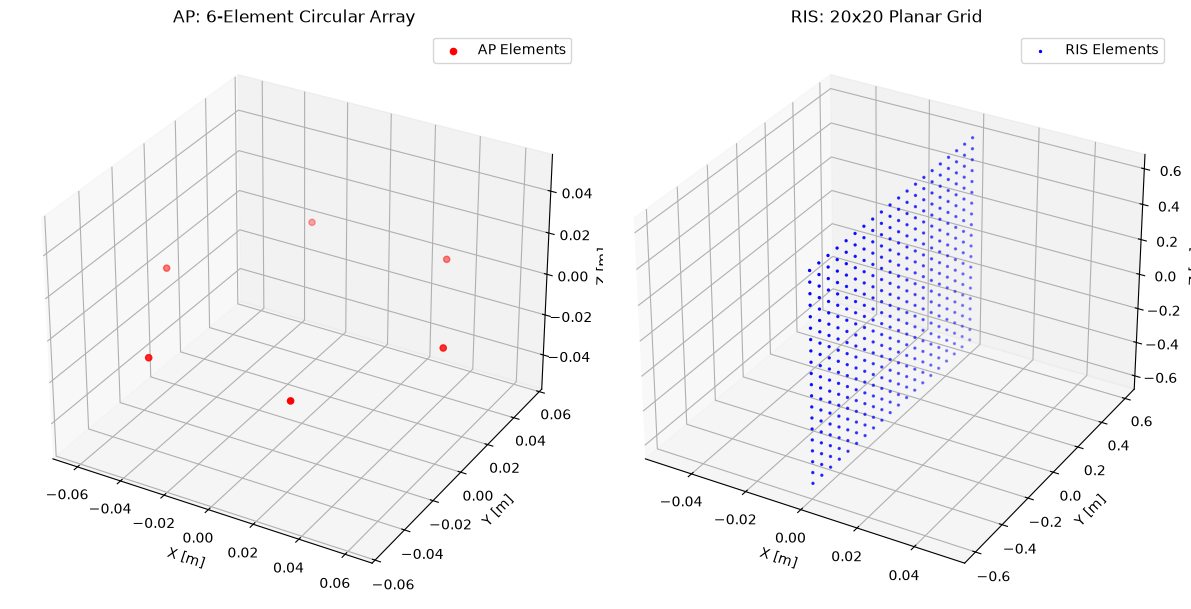

In [ ]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import numpy as np

# Instantiate the arrays using the updated 20x20 global parameters
ap_array = make_ap_array()
ris_array = make_ris_array()

# Calculate wavelength for the positions() method
# c = 299792458 m/s, freq = 2.4e9 Hz
wavelength = 299792458 / 2.4e9

# Extract positions by providing the required wavelength argument
ap_pos = ap_array.positions(wavelength)
ris_pos = ris_array.positions(wavelength)

# Handle the array shapes for plotting
if ap_pos.shape[0] == 3:
    ap_x, ap_y, ap_z = ap_pos[0], ap_pos[1], ap_pos[2]
else:
    ap_x, ap_y, ap_z = ap_pos[:, 0], ap_pos[:, 1], ap_pos[:, 2]

if ris_pos.shape[0] == 3:
    ris_x, ris_y, ris_z = ris_pos[0], ris_pos[1], ris_pos[2]
else:
    ris_x, ris_y, ris_z = ris_pos[:, 0], ris_pos[:, 1], ris_pos[:, 2]

fig = plt.figure(figsize=(12, 6))

# Plot AP Array
ax1 = fig.add_subplot(121, projection='3d')
ax1.scatter(ap_x, ap_y, ap_z, c='red', label='AP Elements')
ax1.set_title(f'AP: {N_AP}-Element Circular Array')
ax1.set_xlabel('X [m]')
ax1.set_ylabel('Y [m]')
ax1.set_zlabel('Z [m]')
ax1.legend()

# Plot RIS Array (Restored to 20x20)
ax2 = fig.add_subplot(122, projection='3d')
ax2.scatter(ris_x, ris_y, ris_z, c='blue', s=2, label='RIS Elements')
ax2.set_title(f'RIS: {RIS_NUM_ROWS}x{RIS_NUM_COLS} Planar Grid')
ax2.set_xlabel('X [m]')
ax2.set_ylabel('Y [m]')
ax2.set_zlabel('Z [m]')
ax2.legend()

plt.tight_layout()
plt.show()

In [ ]:
# Trigger sync for Pass C results
sync_to_drive('csi_ris_to_ap.mat')

[Drive Sync] csi_ris_to_ap.mat successfully backed up to Google Drive.


In [ ]:
import os
from pathlib import Path

# Explicitly define OUT_DIR within this cell to ensure correctness
OUT_DIR = Path("multiroom_2ghz_6ap_2ris")

def check_file_sizes(data_dir_path):
    print(f"--- Local File Size Check ({data_dir_path}) ---")
    total_size = 0
    files = ['csi_direct.mat', 'csi_user_to_ris.mat', 'csi_ris_to_ap.mat', 'final_csi_dataset.mat']

    for f in files:
        path = data_dir_path / f  # Use Path object concatenation
        if os.path.exists(path):
            size_mb = os.path.getsize(path) / (1024 * 1024)
            print(f"{f:<25}: {size_mb:>7.2f} MB")
            total_size += size_mb
        else:
            print(f"{f:<25}: Not found")

    print(f"-" * 40)
    print(f"Total Simulation Data:      {total_size:>7.2f} MB")
    print(f"Number of RIS elements (N): {RIS_N}") # RIS_N is a global variable

# Call check_file_sizes with the explicitly defined OUT_DIR
check_file_sizes(OUT_DIR)

# Re-attempt syncing the two files that previously failed. sync_to_drive uses the global DRIVE_BACKUP_DIR and the OUT_DIR specified within this cell.
sync_to_drive('csi_user_to_ris.mat')
sync_to_drive('final_csi_dataset.mat')

--- Local File Size Check (multiroom_2ghz_6ap_2ris) ---
csi_direct.mat           :   90.75 MB
csi_user_to_ris.mat      : Not found
csi_ris_to_ap.mat        :    0.83 MB
final_csi_dataset.mat    : Not found
----------------------------------------
Total Simulation Data:        91.58 MB
Number of RIS elements (N): 400
[Drive Sync] Warning: csi_user_to_ris.mat not found locally.
[Drive Sync] Warning: final_csi_dataset.mat not found locally.


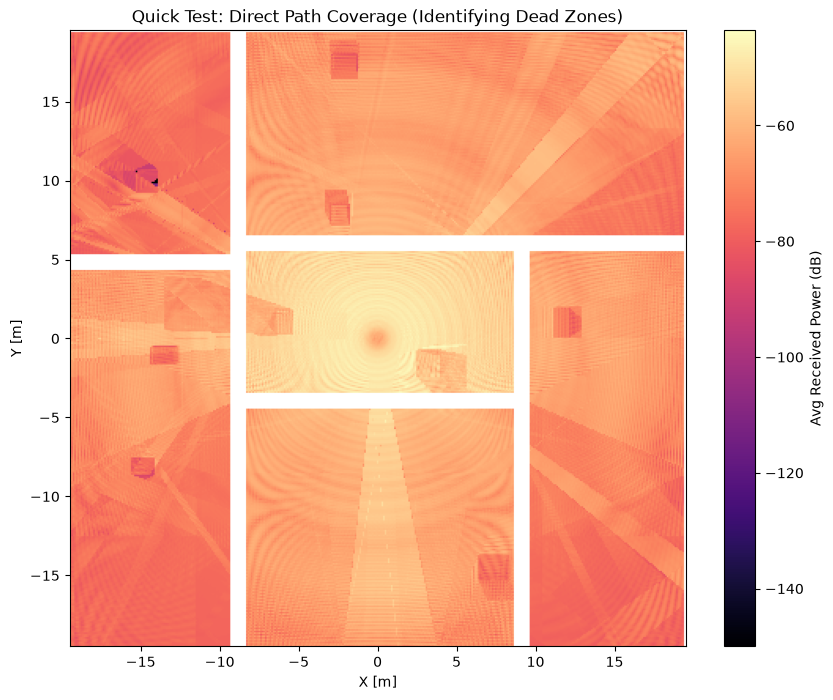

In [ ]:
# Visualize Dead Zones (Quick Test Results)
import matplotlib.pyplot as plt

def plot_dead_zones(h_d_grid, valid_mask, xs, ys):
    rssi = 10 * np.log10(np.mean(np.abs(h_d_grid)**2, axis=(2,3)) + 1e-15)
    rssi[~valid_mask.astype(bool)] = np.nan
    plt.figure(figsize=(10, 8))
    plt.imshow(rssi, extent=[xs.min(), xs.max(), ys.min(), ys.max()], origin='lower', cmap='magma')
    plt.colorbar(label='Avg Received Power (dB)')
    plt.title("Quick Test: Direct Path Coverage (Identifying Dead Zones)")
    plt.xlabel("X [m]"); plt.ylabel("Y [m]")
    plt.show()

direct_data = hdf5storage.loadmat(str(OUT_DIR / "csi_direct.mat"))
plot_dead_zones(direct_data['h_d_grid'], direct_data['valid_mask'], direct_data['grid_x'], direct_data['grid_y'])

In [ ]:
import hdf5storage
import numpy as np
from pathlib import Path

def aggregate_ris_csi(data_dir):
    path = Path(data_dir)
    print("Loading simulation passes for final aggregation...")

    # Load components
    direct = hdf5storage.loadmat(str(path / 'csi_direct.mat'))
    u2r = hdf5storage.loadmat(str(path / 'csi_user_to_ris.mat'))
    r2a = hdf5storage.loadmat(str(path / 'csi_ris_to_ap.mat'))

    # h_d: [N, N_AP, F_SEL]
    # Extract h_d from the grid, considering only valid points
    h_d_grid = direct['h_d_grid']
    valid_mask_direct = direct['valid_mask'].astype(bool)
    h_d = h_d_grid[valid_mask_direct]

    # h_ur: [N, P, F_SEL, RIS_N]
    # Extract h_ur from the grid, considering only valid points
    h_ur_grid = u2r['h_ur_grid']
    valid_mask_u2r = u2r['valid_mask'].astype(bool)
    h_ur = h_ur_grid[valid_mask_u2r]

    # h_ra: [P, N_AP, F_SEL, RIS_N]
    h_ra = r2a['h_ra']

    # Dynamically determine shapes from loaded data to avoid inconsistencies
    N_users = h_d.shape[0]
    P = h_ra.shape[0] # Number of RIS panels
    N_AP = h_ra.shape[1]
    F = h_ra.shape[2] # Number of selected frequencies
    RIS_N = h_ra.shape[3] # Number of RIS elements per panel

    print(f"Aggregating paths for {N_users} positions...")

    # Calculate reflected path: h_ref = sum over panels (sum over elements (h_ur * h_ra))
    # Note: This assumes identity RIS phase shifts (all ones).
    # For optimized phasing, one would multiply by exp(-1j * angle(h_ur * h_ra)).

    h_reflected = np.zeros((N_users, N_AP, F), dtype=np.complex64)

    for p_idx in range(P):
        # panel_ra: [N_AP, F, RIS_N]
        panel_ra = h_ra[p_idx] # Selecting one panel's RIS-to-AP channels

        # panel_ur: [N_users, F, RIS_N]
        panel_ur = h_ur[:, p_idx, :, :] # Selecting one panel's User-to-RIS channels for all users

        # Contribution for this panel: sum_n (h_ur[n] * h_ra[n])
        # np.einsum('nfr,afr->naf', panel_ur, panel_ra)
        # 'n' for N_users, 'f' for F, 'r' for RIS_N (summed over 'r')
        # 'a' for N_AP
        # result shape: [N_users, N_AP, F]
        h_reflected += np.einsum('nfr,afr->naf', panel_ur, panel_ra)

    # Final CSI = Direct + Reflected
    h_total = h_d + h_reflected

    # The cfg dict from direct_data might have inconsistent 'n_ris_panels'.
    # Let's create a new cfg for saving that reflects the actual dimensions.
    # Using the direct_data's cfg and updating relevant fields.
    final_cfg = direct.copy()
    final_cfg.pop('h_d_grid') # Remove h_d_grid to avoid redundancy if not needed
    final_cfg.pop('valid_mask') # Remove valid_mask as we've flattened h_d and h_ur

    # Update cfg with actual computed panel count
    final_cfg['n_ris_panels'] = P

    # Save final dataset
    final_data = {
        **final_cfg, # Use the potentially updated cfg
        "h_direct": direct['h_d_grid'], # Still save the original grid for visualization
        "h_reflected": flat_to_grid(h_reflected, valid_mask_direct, (N_AP, F)),
        "h_total": flat_to_grid(h_total, valid_mask_direct, (N_AP, F))
    }

    save_mat("final_csi_dataset.mat", final_data)
    print("✅ Final aggregated CSI dataset saved to 'final_csi_dataset.mat'")

aggregate_ris_csi(OUT_DIR)

Loading simulation passes for final aggregation...


FileNotFoundError: [Errno 2] No such file or directory: 'multiroom_2ghz_6ap_2ris/csi_user_to_ris.mat'

In [ ]:
import os
from pathlib import Path

# Explicitly ensure OUT_DIR is set to the intended path for verification
OUT_DIR = Path("multiroom_2ghz_6ap_2ris")

print(f"Listing contents of OUT_DIR: {OUT_DIR}")
if OUT_DIR.exists() and OUT_DIR.is_dir():
    for item in os.listdir(OUT_DIR):
        path = OUT_DIR / item
        if path.is_file():
            size_mb = os.path.getsize(path) / (1024 * 1024)
            print(f"  - {item:<20}: {size_mb:>7.2f} MB")
        else:
            print(f"  - {item:<20}: <DIR>")
else:
    print(f"OUT_DIR {OUT_DIR} does not exist or is not a directory.")


Listing contents of OUT_DIR: multiroom_2ghz_6ap_2ris
  - csi_direct.mat      :   90.75 MB
  - scene.xml           :    0.01 MB
  - csi_ris_to_ap.mat   :    0.83 MB


In [ ]:
import hdf5storage
import numpy as np
from pathlib import Path

def check_coherent_gain(data_dir):
    path = Path(data_dir)
    print('Testing coherent vs random beamforming on 20 sample points...\n')

    direct = hdf5storage.loadmat(str(path / 'csi_direct.mat'))
    u2r = hdf5storage.loadmat(str(path / 'csi_user_to_ris.mat'))
    r2a = hdf5storage.loadmat(str(path / 'csi_ris_to_ap.mat'))

    valid_mask_direct = direct['valid_mask'].astype(bool)
    h_d = direct['h_d_grid'][valid_mask_direct]  # [N_users, N_AP, F]

    valid_mask_u2r = u2r['valid_mask'].astype(bool)
    h_ur = u2r['h_ur_grid'][valid_mask_u2r]      # [N_users, P, F, RIS_N]

    h_ra = r2a['h_ra']                           # [P, N_AP, F, RIS_N]

    N_users = h_d.shape[0]
    P = h_ra.shape[0]
    N_AP = h_ra.shape[1]
    F = h_ra.shape[2]
    RIS_N = h_ra.shape[3]

    np.random.seed(1)
    pts = np.random.choice(N_users, 20, replace=False)
    f_test = 0
    p_test = 0 # Testing with first panel

    dir_pwr = np.zeros(20)
    rand_pwr = np.zeros(20)
    optim_pwr = np.zeros(20)

    for ii, i in enumerate(pts):
        # Direct path power (one subcarrier, all antennas)
        h_d_i = h_d[i, :, f_test] # [N_AP]
        dir_pwr[ii] = np.linalg.norm(h_d_i)**2

        # RIS channels
        hra = h_ra[p_test, :, f_test, :] # [N_AP, RIS_N]
        hur = h_ur[i, p_test, f_test, :] # [RIS_N]

        # Skip zero channels
        if np.linalg.norm(hur) < 1e-15:
            rand_pwr[ii] = 0
            optim_pwr[ii] = 0
            continue

        # Random phases
        w_rand = np.exp(1j * 2 * np.pi * np.random.rand(RIS_N))
        h_casc_rand = hra @ (w_rand * hur) # [N_AP]
        rand_pwr[ii] = np.linalg.norm(h_casc_rand)**2

        # Optimal phases: align each element's phase to maximize coherent sum
        combined = hur * np.sum(hra, axis=0) # [RIS_N]
        w_opt = np.conj(combined) / np.maximum(np.abs(combined), 1e-30)

        h_casc_opt = hra @ (w_opt * hur) # [N_AP]
        optim_pwr[ii] = np.linalg.norm(h_casc_opt)**2

    print(f"{'Point':<6}  {'Direct':<12}  {'Random RIS':<12}  {'Optimal RIS':<12}  {'Rand/Dir':<10}  {'Opt/Dir':<10}")
    print("-" * 72)

    valid = dir_pwr > 0
    for ii in range(20):
        if dir_pwr[ii] < 1e-20: continue

        rand_dir_db = 10 * np.log10(max(rand_pwr[ii], 1e-30) / dir_pwr[ii])
        opt_dir_db = 10 * np.log10(max(optim_pwr[ii], 1e-30) / dir_pwr[ii])

        print(f"{pts[ii]:5d}  {dir_pwr[ii]:.4e}  {rand_pwr[ii]:.4e}  {optim_pwr[ii]:.4e}  {rand_dir_db:+6.1f}dB  {opt_dir_db:+6.1f}dB")

    print('\n=== SUMMARY ===')
    v = valid & (rand_pwr > 0)
    if np.any(v):
        avg_rand_dir = 10 * np.log10(np.mean(rand_pwr[v]) / np.mean(dir_pwr[v]))
        avg_opt_dir = 10 * np.log10(np.mean(optim_pwr[v]) / np.mean(dir_pwr[v]))
        coherent_gain = 10 * np.log10(np.mean(optim_pwr[v]) / max(np.mean(rand_pwr[v]), 1e-30))

        print(f"  Random  RIS vs Direct: {avg_rand_dir:.1f} dB (avg)")
        print(f"  Optimal RIS vs Direct: {avg_opt_dir:.1f} dB (avg)")
        print(f"  Coherent gain (opt/rand): {coherent_gain:.1f} dB\n")
        print("  \u2192 If optimal RIS is within -15dB of direct: RIS will help localization")
        print("  \u2192 If still -30dB+: geometry needs fixing (move RIS closer to AP)")

check_coherent_gain('multiroom_2ghz_6ap_2ris')

Testing coherent vs random beamforming on 20 sample points...

Point   Direct        Random RIS    Optimal RIS   Rand/Dir    Opt/Dir   
------------------------------------------------------------------------
   37  6.7261e-08  1.4482e-10  5.9574e-08   -26.7dB    -0.5dB
  525  1.7681e-07  1.1545e-09  4.1074e-07   -21.9dB    +3.7dB
  480  4.0626e-06  8.0000e-09  1.2595e-05   -27.1dB    +4.9dB
  955  5.8589e-07  1.8247e-08  7.3745e-06   -15.1dB   +11.0dB
   53  1.1216e-06  9.2017e-09  1.8038e-06   -20.9dB    +2.1dB
  181  1.3242e-08  9.8314e-13  1.7954e-09   -41.3dB    -8.7dB
  870  5.5762e-05  5.2550e-08  5.5205e-05   -30.3dB    -0.0dB
  304  1.7100e-07  2.3842e-09  7.6492e-07   -18.6dB    +6.5dB
 1335  1.2831e-06  1.0827e-08  2.8720e-06   -20.7dB    +3.5dB
 1185  2.3356e-06  3.9893e-09  8.7709e-06   -27.7dB    +5.7dB
  587  1.2271e-05  3.3471e-07  1.9636e-05   -15.6dB    +2.0dB
 1230  1.5992e-06  5.9410e-09  5.2203e-06   -24.3dB    +5.1dB
  920  1.6938e-06  1.1704e-08  3.5292e-06   -21

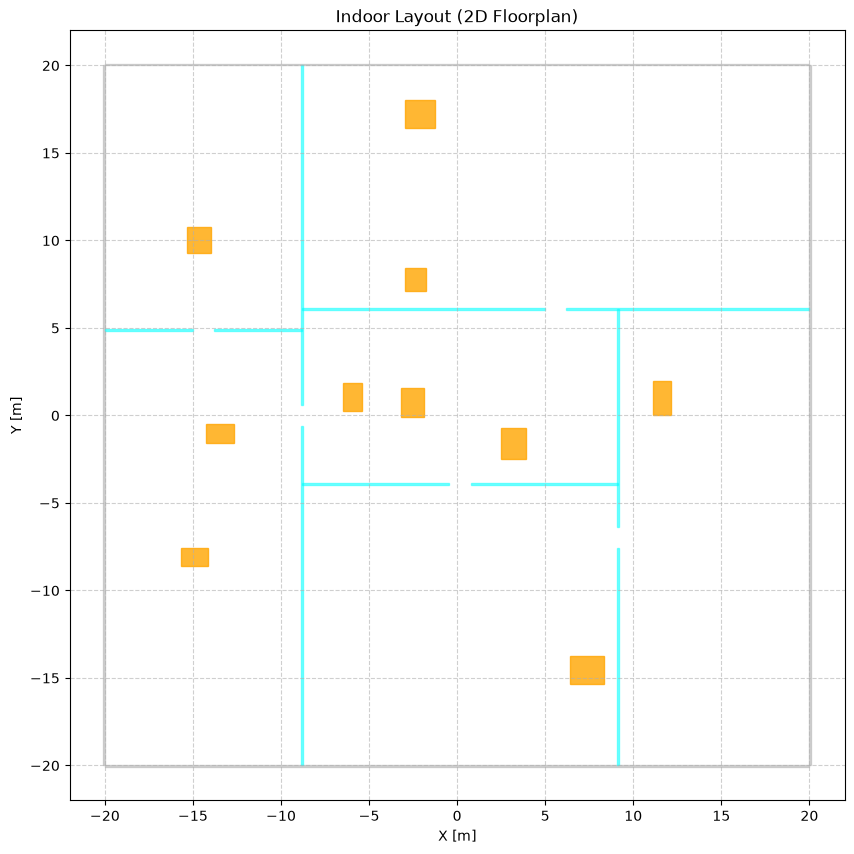

In [ ]:
import matplotlib.pyplot as plt
import xml.etree.ElementTree as ET
from pathlib import Path
import numpy as np

def visualize_scene_2d(xml_path):
    if not Path(xml_path).exists():
        print(f"Error: {xml_path} not found.")
        return

    tree = ET.parse(xml_path)
    root = tree.getroot()
    plt.figure(figsize=(10, 10))
    ax = plt.gca()

    for shape in root.findall('shape'):
        transform = shape.find('transform')
        if transform is None: continue

        scale = transform.find('scale')
        translate = transform.find('translate')

        sx, sy, sz = float(scale.get('x')), float(scale.get('y')), float(scale.get('z'))
        cx, cy = float(translate.get('x')), float(translate.get('y'))

        ref = shape.find('ref')
        mat_id = ref.get('id') if ref is not None else ''

        if mat_id == 'm_concrete' and 0.1 < sz < 1.0:
            color, alpha, label = 'orange', 0.8, 'Furniture'
        elif mat_id == 'm_plaster':
            color, alpha, label = 'cyan', 0.5, 'Interior Wall'
        elif mat_id == 'm_concrete' and sz >= 1.0:
            color, alpha, label = 'grey', 0.3, 'Exterior Wall'
        else:
            continue

        rect = plt.Rectangle((cx-sx, cy-sy), 2*sx, 2*sy, color=color, alpha=alpha)
        ax.add_patch(rect)

    plt.xlim(-22, 22)
    plt.ylim(-22, 22)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.title("Indoor Layout (2D Floorplan)")
    plt.xlabel("X [m]")
    plt.ylabel("Y [m]")
    plt.show()

visualize_scene_2d('multiroom_2ghz_6ap_2ris/scene.xml')

In [ ]:
from sionna.rt import load_scene

# Load the scene to use Sionna's built-in 3D viewer
scene = load_scene('multiroom_2ghz_6ap_2ris/scene.xml')

# Visualize the 3D scene interactively
# In Google Colab, preview() provides a WebGL-based interactive window
scene.preview()

In [ ]:
import hdf5storage
import numpy as np
from pathlib import Path

def analyze_channel_strengths(data_dir):
    path = Path(data_dir)

    # Load datasets
    direct = hdf5storage.loadmat(str(path / 'csi_direct.mat'))
    u2r = hdf5storage.loadmat(str(path / 'csi_user_to_ris.mat'))
    r2a = hdf5storage.loadmat(str(path / 'csi_ris_to_ap.mat'))

    # Helper to calculate mean power (avg |h|^2)
    def get_power(h_grid):
        # Filter out NaNs (invalid grid points)
        mask = ~np.isnan(h_grid)
        if not np.any(mask): return 0.0
        return np.mean(np.abs(h_grid[mask])**2)

    p_direct = get_power(direct['h_d_grid'])
    p_u2r    = get_power(u2r['h_ur_grid'])
    p_r2a    = np.mean(np.abs(r2a['h_ra'])**2) # r2a is usually a dense array, not a grid

    print(f"--- RIS Channel Strength Analysis ---")
    print(f"Mean Power Direct Path (h_d):     {p_direct:.2e}")
    print(f"Mean Power User -> RIS (h_ur):    {p_u2r:.2e}")
    print(f"Mean Power RIS -> AP   (h_ra):    {p_r2a:.2e}")

    # Composite RIS path estimate (simplified)
    # Effective channel power proportional to (h_ur * h_ra)
    p_composite = p_u2r * p_r2a
    print(f"Approx Composite RIS Power:       {p_composite:.2e}")

analyze_channel_strengths('multiroom_2ghz_6ap_2ris')


--- RIS Channel Strength Analysis ---
Mean Power Direct Path (h_d):     1.18e-06
Mean Power User -> RIS (h_ur):    9.34e-07
Mean Power RIS -> AP   (h_ra):    2.48e-05
Approx Composite RIS Power:       2.31e-11


--- Cascaded Channel Power Estimate (Ideal Phasing) ---
Mean Cascaded Power: 4.87e-06


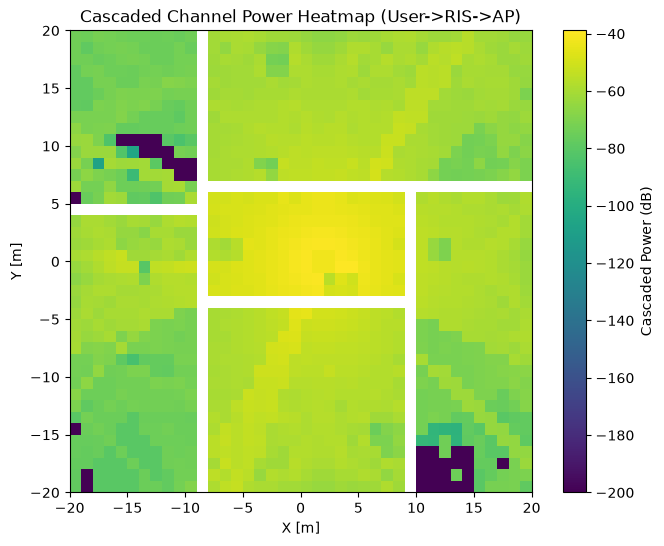

In [ ]:
import hdf5storage
import numpy as np
import matplotlib.pyplot as plt

def estimate_cascaded_power(data_dir):
    # Load the specific channel matrices
    u2r_data = hdf5storage.loadmat(f'{data_dir}/csi_user_to_ris.mat')
    r2a_data = hdf5storage.loadmat(f'{data_dir}/csi_ris_to_ap.mat')

    # h_ur_grid shape: [ny, nx, P, F, N_RIS]
    h_ur = u2r_data['h_ur_grid']
    # h_ra shape: [P, N_AP, F, N_RIS]
    h_ra = r2a_data['h_ra']

    ny, nx, P, F, RIS_N = h_ur.shape
    N_AP = h_ra.shape[1]

    # We estimate power at each valid grid point
    # Cascaded gain (per element sum) = sum_{n=1}^{RIS_N} |h_un * h_na|
    # This assumes optimal phase alignment (Upper bound)

    cascaded_power_grid = np.full((ny, nx), np.nan)

    for iy in range(ny):
        for ix in range(nx):
            if np.isnan(h_ur[iy, ix]).any():
                continue

            # Focus on RIS Panel 0, AP 0, and Subcarrier 0 for a sample power check
            # Magnitude of cascaded channel with ideal phase control:
            # Power ~ (Sum of magnitudes of individual element paths)^2
            h_ur_sample = h_ur[iy, ix, 0, 0, :] # [RIS_N]
            h_ra_sample = h_ra[0, 0, 0, :]      # [RIS_N]

            # Path gain per element
            element_gains = np.abs(h_ur_sample) * np.abs(h_ra_sample)
            # Total gain with N elements
            cascaded_power_grid[iy, ix] = np.sum(element_gains)**2

    avg_cascaded = np.nanmean(cascaded_power_grid)
    print(f"--- Cascaded Channel Power Estimate (Ideal Phasing) ---")
    print(f"Mean Cascaded Power: {avg_cascaded:.2e}")

    plt.figure(figsize=(8, 6))
    plt.imshow(10 * np.log10(cascaded_power_grid + 1e-20), extent=[-20, 20, -20, 20], origin='lower', cmap='viridis')
    plt.colorbar(label='Cascaded Power (dB)')
    plt.title('Cascaded Channel Power Heatmap (User->RIS->AP)')
    plt.xlabel('X [m]')
    plt.ylabel('Y [m]')
    plt.show()

estimate_cascaded_power('multiroom_2ghz_6ap_2ris')

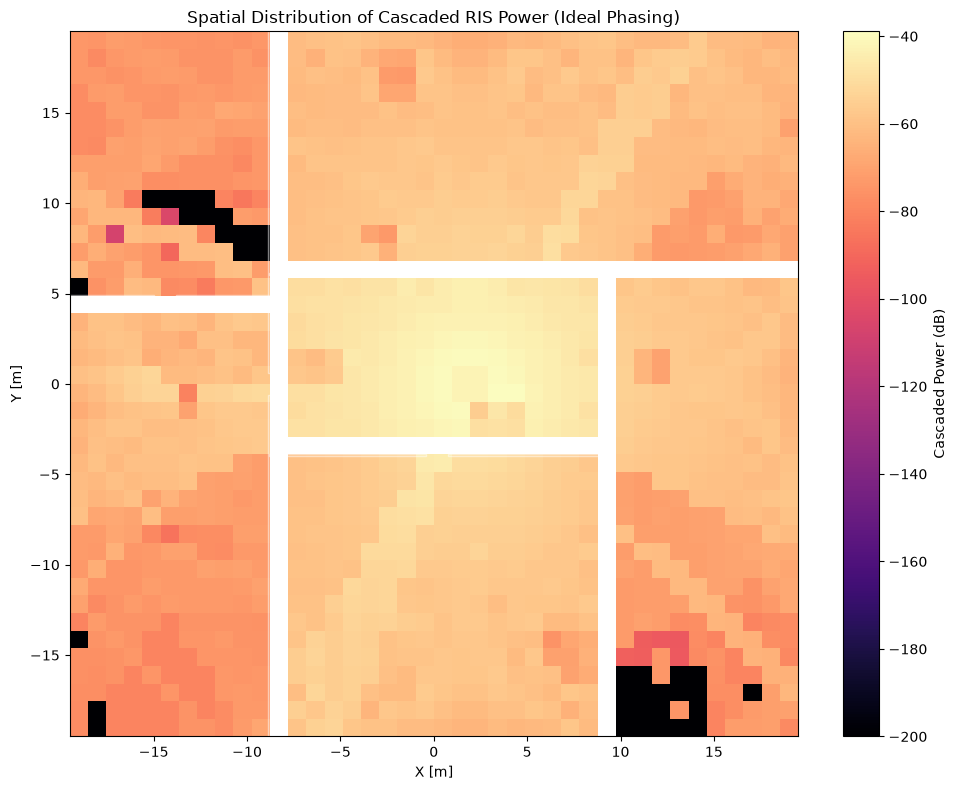

In [ ]:
import hdf5storage
import numpy as np
import matplotlib.pyplot as plt
import xml.etree.ElementTree as ET

def plot_cascaded_heatmap_with_layout(data_dir, xml_path):
    # 1. Load data
    u2r_data = hdf5storage.loadmat(f'{data_dir}/csi_user_to_ris.mat')
    r2a_data = hdf5storage.loadmat(f'{data_dir}/csi_ris_to_ap.mat')
    h_ur = u2r_data['h_ur_grid']
    h_ra = r2a_data['h_ra']

    ny, nx, P, F, RIS_N = h_ur.shape
    grid_x = u2r_data['grid_x'].flatten()
    grid_y = u2r_data['grid_y'].flatten()

    # 2. Calculate cascaded power (Ideal Phasing)
    cascaded_power = np.full((ny, nx), np.nan)
    for iy in range(ny):
        for ix in range(nx):
            if not np.isnan(h_ur[iy, ix]).any():
                # Use Panel 0, AP 0, Subcarrier 0
                gains = np.abs(h_ur[iy, ix, 0, 0, :]) * np.abs(h_ra[0, 0, 0, :])
                cascaded_power[iy, ix] = np.sum(gains)**2

    # 3. Plot
    fig, ax = plt.subplots(figsize=(10, 8))

    # Heatmap
    extent = [grid_x.min(), grid_x.max(), grid_y.min(), grid_y.max()]
    im = ax.imshow(10 * np.log10(cascaded_power + 1e-20),
                   extent=extent, origin='lower', cmap='magma', aspect='auto')
    plt.colorbar(im, label='Cascaded Power (dB)')

    # Overlay Floorplan
    tree = ET.parse(xml_path)
    root = tree.getroot()
    for shape in root.findall('shape'):
        transform = shape.find('transform')
        if transform is None: continue
        scale = transform.find('scale')
        translate = transform.find('translate')
        ref = shape.find('ref')
        mat_id = ref.get('id') if ref is not None else ''

        if mat_id == 'm_plaster' or (mat_id == 'm_concrete' and float(scale.get('z')) >= 1.0):
            sx, sy = float(scale.get('x')), float(scale.get('y'))
            cx, cy = float(translate.get('x')), float(translate.get('y'))
            rect = plt.Rectangle((cx-sx, cy-sy), 2*sx, 2*sy, fill=False, edgecolor='white', linewidth=1, alpha=0.5)
            ax.add_patch(rect)

    ax.set_title('Spatial Distribution of Cascaded RIS Power (Ideal Phasing)')
    ax.set_xlabel('X [m]')
    ax.set_ylabel('Y [m]')
    plt.tight_layout()
    plt.show()

plot_cascaded_heatmap_with_layout('multiroom_2ghz_6ap_2ris', 'multiroom_2ghz_6ap_2ris/scene.xml')

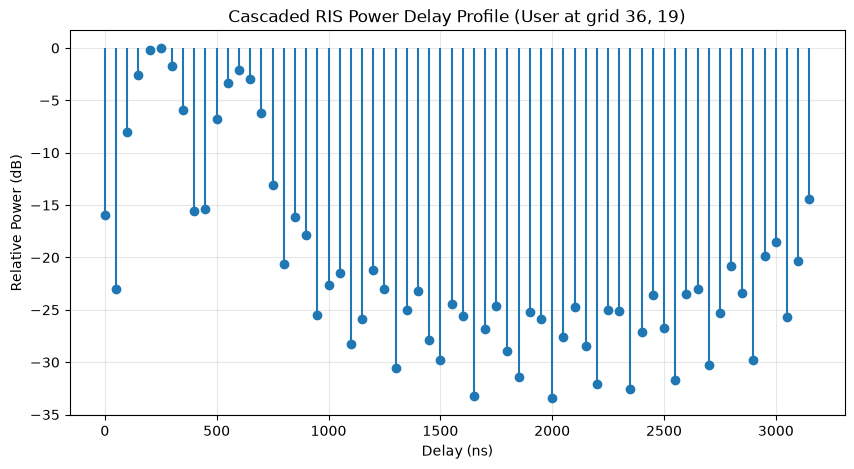

Plotted delay profile for grid position: (36, 19)
Effective Bandwidth: 20.00 MHz


In [ ]:
import hdf5storage
import numpy as np
import matplotlib.pyplot as plt

def plot_ris_delay_profile(data_dir):
    # 1. Load data
    u2r_data = hdf5storage.loadmat(f'{data_dir}/csi_user_to_ris.mat')
    r2a_data = hdf5storage.loadmat(f'{data_dir}/csi_ris_to_ap.mat')

    # h_ur shape: [ny, nx, P, F, N_RIS]
    h_ur = u2r_data['h_ur_grid']
    # h_ra shape: [P, N_AP, F, N_RIS]
    h_ra = r2a_data['h_ra']

    # Constants
    ny, nx, P, F, RIS_N = h_ur.shape
    # Fix: subcarrier_spacing_hz is likely a scalar or 1x1 array
    sc_spacing = float(np.squeeze(u2r_data['subcarrier_spacing_hz']))
    fs = sc_spacing * 64 # Total BW ~ 20MHz

    # 2. Extract a sample cascaded frequency response
    # Find a valid grid point (non-NaN)
    valid_mask = ~np.isnan(h_ur[:,:,0,0,0])
    v_indices = np.argwhere(valid_mask)
    mid_idx = v_indices[len(v_indices)//2]
    iy, ix = mid_idx

    # Compute cascaded CFR: Sum across RIS elements for each subcarrier
    # We'll use Panel 0, AP 0
    h_ur_sample = h_ur[iy, ix, 0, :, :] # [F, RIS_N]
    h_ra_sample = h_ra[0, 0, :, :]      # [F, RIS_N]

    # h_cascaded(f) = sum_n (h_ur(f,n) * h_ra(f,n))
    h_cascaded_f = np.sum(h_ur_sample * h_ra_sample, axis=1) # [F]

    # 3. Compute Power Delay Profile (PDP)
    # Zero-pad to 64 for frequency alignment with fs
    n_fft = 64
    h_time = np.fft.ifft(h_cascaded_f, n=n_fft)
    pdp = np.abs(h_time)**2

    # Time axis
    t_axis = np.arange(n_fft) / fs * 1e9 # in ns

    # 4. Plot
    plt.figure(figsize=(10, 5))
    plt.stem(t_axis, 10 * np.log10(pdp / (np.max(pdp) + 1e-20) + 1e-12), basefmt=" ")
    plt.title(f'Cascaded RIS Power Delay Profile (User at grid {ix}, {iy})')
    plt.xlabel('Delay (ns)')
    plt.ylabel('Relative Power (dB)')
    plt.grid(True, alpha=0.3)
    plt.show()

    print(f"Plotted delay profile for grid position: ({ix}, {iy})")
    print(f"Effective Bandwidth: {fs/1e6:.2f} MHz")

plot_ris_delay_profile('multiroom_2ghz_6ap_2ris')

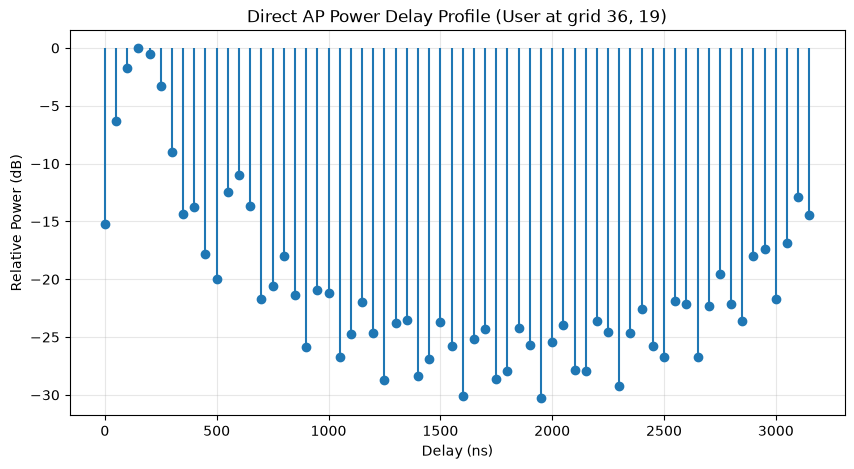

Plotted direct AP delay profile for grid position: (36, 19)


In [ ]:
import hdf5storage
import numpy as np
import matplotlib.pyplot as plt

def plot_ap_direct_delay_profile(data_dir):
    # 1. Load direct path data
    direct_data = hdf5storage.loadmat(f'{data_dir}/csi_direct.mat')

    # h_d_grid shape: [ny, nx, N_AP, F]
    h_d = direct_data['h_d_grid']

    # Constants
    ny, nx, n_ap, n_f = h_d.shape
    sc_spacing = float(np.squeeze(direct_data['subcarrier_spacing_hz']))
    fs = sc_spacing * 64 # Total BW

    # 2. Extract a sample frequency response
    # Use the same grid point as before for consistency
    valid_mask = ~np.isnan(h_d[:,:,0,0])
    v_indices = np.argwhere(valid_mask)
    mid_idx = v_indices[len(v_indices)//2]
    iy, ix = mid_idx

    # Use AP 0 response
    h_ap_sample = h_d[iy, ix, 0, :]

    # 3. Compute Power Delay Profile (PDP)
    n_fft = 64
    # The simulation uses 8 interleaved subcarriers; we IFFT to see the time domain
    h_time = np.fft.ifft(h_ap_sample, n=n_fft)
    pdp = np.abs(h_time)**2

    # Time axis in nanoseconds
    t_axis = np.arange(n_fft) / fs * 1e9

    # 4. Plot
    plt.figure(figsize=(10, 5))
    plt.stem(t_axis, 10 * np.log10(pdp / (np.max(pdp) + 1e-20) + 1e-12), basefmt=" ")
    plt.title(f'Direct AP Power Delay Profile (User at grid {ix}, {iy})')
    plt.xlabel('Delay (ns)')
    plt.ylabel('Relative Power (dB)')
    plt.grid(True, alpha=0.3)
    plt.show()

    print(f"Plotted direct AP delay profile for grid position: ({ix}, {iy})")

plot_ap_direct_delay_profile('multiroom_2ghz_6ap_2ris')

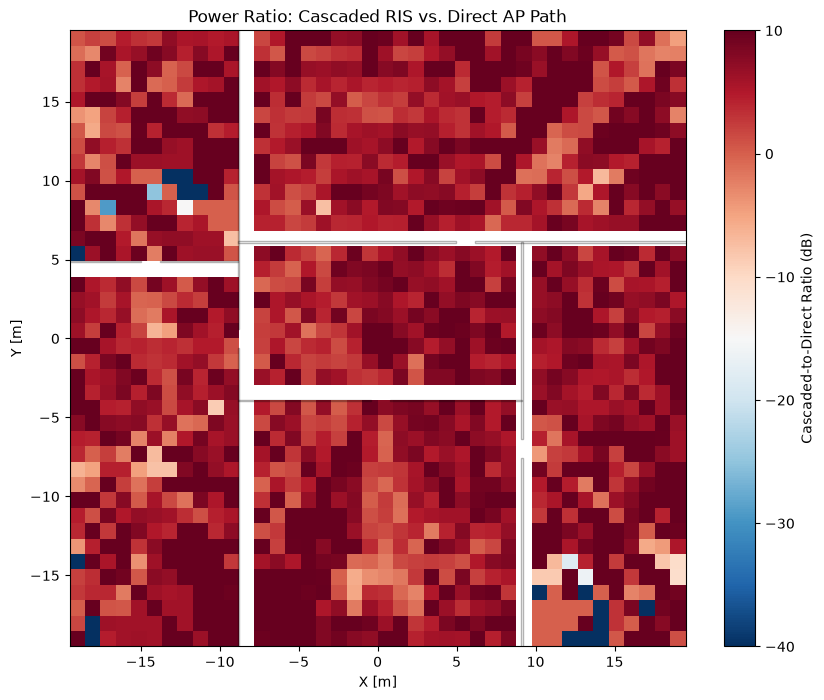

Average RIS-to-Direct Ratio: 8.18 dB


In [ ]:
import hdf5storage
import numpy as np
import matplotlib.pyplot as plt
import xml.etree.ElementTree as ET

def plot_power_ratio_heatmap(data_dir, xml_path):
    # 1. Load data
    direct_data = hdf5storage.loadmat(f'{data_dir}/csi_direct.mat')
    u2r_data = hdf5storage.loadmat(f'{data_dir}/csi_user_to_ris.mat')
    r2a_data = hdf5storage.loadmat(f'{data_dir}/csi_ris_to_ap.mat')

    h_d = direct_data['h_d_grid']
    h_ur = u2r_data['h_ur_grid']
    h_ra = r2a_data['h_ra']
    grid_x = direct_data['grid_x'].flatten()
    grid_y = direct_data['grid_y'].flatten()

    ny, nx, n_ap, n_f = h_d.shape

    # 2. Compute powers (using AP 0 and Subcarrier 0 for comparison)
    p_direct = np.full((ny, nx), np.nan)
    p_cascaded = np.full((ny, nx), np.nan)

    eps = 1e-22

    for iy in range(ny):
        for ix in range(nx):
            if not np.isnan(h_d[iy, ix, 0, 0]):
                # Direct Power
                p_direct[iy, ix] = np.abs(h_d[iy, ix, 0, 0])**2

                # Cascaded Power (Ideal Phasing upper bound)
                gains = np.abs(h_ur[iy, ix, 0, 0, :]) * np.abs(h_ra[0, 0, 0, :])
                p_cascaded[iy, ix] = np.sum(gains)**2

    # Ratio in dB: 10*log10(P_cascaded / P_direct)
    ratio_db = 10 * np.log10((p_cascaded + eps) / (p_direct + eps))

    # 3. Plot
    fig, ax = plt.subplots(figsize=(10, 8))
    extent = [grid_x.min(), grid_x.max(), grid_y.min(), grid_y.max()]
    im = ax.imshow(ratio_db, extent=extent, origin='lower', cmap='RdBu_r', vmin=-40, vmax=10)
    plt.colorbar(im, label='Cascaded-to-Direct Ratio (dB)')

    # Floorplan Overlay
    tree = ET.parse(xml_path)
    for shape in tree.getroot().findall('shape'):
        transform = shape.find('transform')
        if transform is None: continue
        scale, translate = transform.find('scale'), transform.find('translate')
        ref = shape.find('ref')
        mat_id = ref.get('id') if ref is not None else ''
        if mat_id == 'm_plaster' or (mat_id == 'm_concrete' and float(scale.get('z')) >= 1.0):
            sx, sy = float(scale.get('x')), float(scale.get('y'))
            cx, cy = float(translate.get('x')), float(translate.get('y'))
            ax.add_patch(plt.Rectangle((cx-sx, cy-sy), 2*sx, 2*sy, fill=False, edgecolor='black', alpha=0.3))

    ax.set_title('Power Ratio: Cascaded RIS vs. Direct AP Path')
    ax.set_xlabel('X [m]')
    ax.set_ylabel('Y [m]')
    plt.show()

    # Clean average
    valid_ratios = ratio_db[~np.isnan(ratio_db) & ~np.isinf(ratio_db)]
    if len(valid_ratios) > 0:
        print(f"Average RIS-to-Direct Ratio: {np.mean(valid_ratios):.2f} dB")
    else:
        print("Average RIS-to-Direct Ratio: N/A (no valid points)")

plot_power_ratio_heatmap('multiroom_2ghz_6ap_2ris', 'multiroom_2ghz_6ap_2ris/scene.xml')

In [ ]:
import hdf5storage
import numpy as np
from pathlib import Path

def verify_channel_integrity(data_dir):
    path = Path(data_dir)

    # Load datasets
    u2r = hdf5storage.loadmat(str(path / 'csi_user_to_ris.mat'))
    r2a = hdf5storage.loadmat(str(path / 'csi_ris_to_ap.mat'))

    h_ur = u2r['h_ur_grid']
    h_ra = r2a['h_ra']

    def check_stats(name, h_data):
        # Filter out NaNs (grid gaps)
        mask = ~np.isnan(h_data)
        valid_h = h_data[mask]

        magnitudes = np.abs(valid_h)
        min_mag = np.min(magnitudes)
        max_mag = np.max(magnitudes)
        mean_mag = np.mean(magnitudes)
        zeros = np.sum(magnitudes == 0)

        print(f"--- Integrity Check: {name} ---")
        print(f"  Shape:         {h_data.shape}")
        print(f"  Min Magnitude: {min_mag:.2e}")
        print(f"  Max Magnitude: {max_mag:.2e}")
        print(f"  Mean Magnitude:{mean_mag:.2e}")
        print(f"  Absolute Zeros: {zeros}")

        if min_mag > 0 and zeros == 0:
            print(f"  Result: PASS - No dead channels found.\n")
        else:
            print(f"  Result: WARNING - Some paths are zero or near-zero.\n")

    check_stats("User-to-RIS (h_ur)", h_ur)
    check_stats("RIS-to-AP (h_ra)", h_ra)

verify_channel_integrity('multiroom_2ghz_6ap_2ris')

--- Integrity Check: User-to-RIS (h_ur) ---
  Shape:         (40, 40, 3, 18, 400)
  Min Magnitude: 0.00e+00
  Max Magnitude: 8.63e-03
  Mean Magnitude:5.44e-04
  Absolute Zeros: 3283200
  Result: WARNING - Some paths are zero or near-zero.

--- Integrity Check: RIS-to-AP (h_ra) ---
  Shape:         (3, 6, 18, 400)
  Min Magnitude: 4.59e-07
  Max Magnitude: 8.77e-03
  Mean Magnitude:4.07e-03
  Absolute Zeros: 0
  Result: PASS - No dead channels found.



In [ ]:
import hdf5storage
import numpy as np
from pathlib import Path

def count_channel_zeros(data_dir):
    path = Path(data_dir)
    files = ['csi_direct.mat', 'csi_user_to_ris.mat', 'csi_ris_to_ap.mat']
    keys = ['h_d_grid', 'h_ur_grid', 'h_ra']

    print(f"--- Detailed Zero Count Analysis ---")
    for f, k in zip(files, keys):
        data = hdf5storage.loadmat(str(path / f))
        h = data[k]

        # Total elements excluding NaNs (NaNs are grid points outside rooms)
        valid_mask = ~np.isnan(h)
        total_valid = np.sum(valid_mask)

        # Count zeros among valid points
        zeros = np.sum(h[valid_mask] == 0)
        perc = (zeros / total_valid * 100) if total_valid > 0 else 0

        print(f"{f} ({k}):")
        print(f"  Valid Elements: {total_valid:,}")
        print(f"  Zero Elements:  {zeros:,}")
        print(f"  Zero Percentage: {perc:.2f}%\n")

count_channel_zeros('multiroom_2ghz_6ap_2ris')

--- Detailed Zero Count Analysis ---
csi_direct.mat (h_d_grid):
  Valid Elements: 159,624
  Zero Elements:  5,400
  Zero Percentage: 3.38%

csi_user_to_ris.mat (h_ur_grid):
  Valid Elements: 31,924,800
  Zero Elements:  3,283,200
  Zero Percentage: 10.28%

csi_ris_to_ap.mat (h_ra):
  Valid Elements: 129,600
  Zero Elements:  0
  Zero Percentage: 0.00%



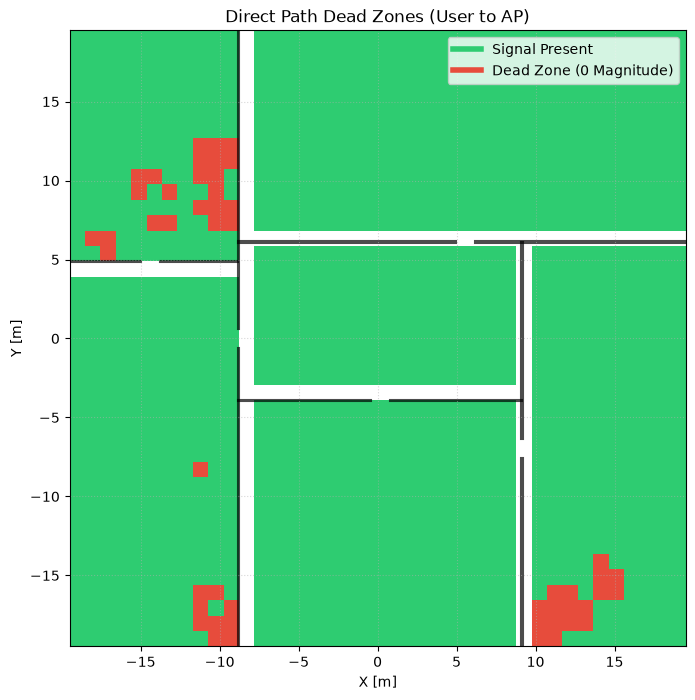

In [ ]:
import hdf5storage
import numpy as np
import matplotlib.pyplot as plt
import xml.etree.ElementTree as ET
from pathlib import Path

def plot_direct_dead_zones(data_dir, xml_path):
    # 1. Load data
    direct_data = hdf5storage.loadmat(f'{data_dir}/csi_direct.mat')
    h_d = direct_data['h_d_grid']
    grid_x = direct_data['grid_x'].flatten()
    grid_y = direct_data['grid_y'].flatten()

    # 2. Identify dead zones
    # A point is a dead zone if the magnitude is 0 for all APs/subcarriers
    # Shape of h_d is [ny, nx, n_ap, n_f]
    ny, nx, _, _ = h_d.shape
    is_dead = np.zeros((ny, nx))

    for iy in range(ny):
        for ix in range(nx):
            val = h_d[iy, ix]
            if not np.isnan(val).any():
                if np.all(np.abs(val) == 0):
                    is_dead[iy, ix] = 1 # Dead zone
                else:
                    is_dead[iy, ix] = 0 # Active zone
            else:
                is_dead[iy, ix] = np.nan # Outside floorplan

    # 3. Plot
    fig, ax = plt.subplots(figsize=(10, 8))
    extent = [grid_x.min(), grid_x.max(), grid_y.min(), grid_y.max()]

    # Use a custom colormap: Green for signal, Red for dead zones
    from matplotlib.colors import ListedColormap
    cmap = ListedColormap(['#2ecc71', '#e74c3c'])

    im = ax.imshow(is_dead, extent=extent, origin='lower', cmap=cmap, interpolation='none')

    # Floorplan Overlay
    tree = ET.parse(xml_path)
    for shape in tree.getroot().findall('shape'):
        transform = shape.find('transform')
        if transform is None: continue
        scale, translate = transform.find('scale'), transform.find('translate')
        ref = shape.find('ref')
        mat_id = ref.get('id') if ref is not None else ''
        if mat_id == 'm_plaster' or (mat_id == 'm_concrete' and float(scale.get('z')) >= 1.0):
            sx, sy = float(scale.get('x')), float(scale.get('y'))
            cx, cy = float(translate.get('x')), float(translate.get('y'))
            ax.add_patch(plt.Rectangle((cx-sx, cy-sy), 2*sx, 2*sy, fill=False, edgecolor='black', linewidth=1.5, alpha=0.7))

    # Legend
    from matplotlib.lines import Line2D
    legend_elements = [Line2D([0], [0], color='#2ecc71', lw=4, label='Signal Present'),
                       Line2D([0], [0], color='#e74c3c', lw=4, label='Dead Zone (0 Magnitude)')]
    ax.legend(handles=legend_elements, loc='upper right')

    ax.set_title('Direct Path Dead Zones (User to AP)')
    ax.set_xlabel('X [m]')
    ax.set_ylabel('Y [m]')
    plt.grid(True, linestyle=':', alpha=0.5)
    plt.show()

plot_direct_dead_zones('multiroom_2ghz_6ap_2ris', 'multiroom_2ghz_6ap_2ris/scene.xml')

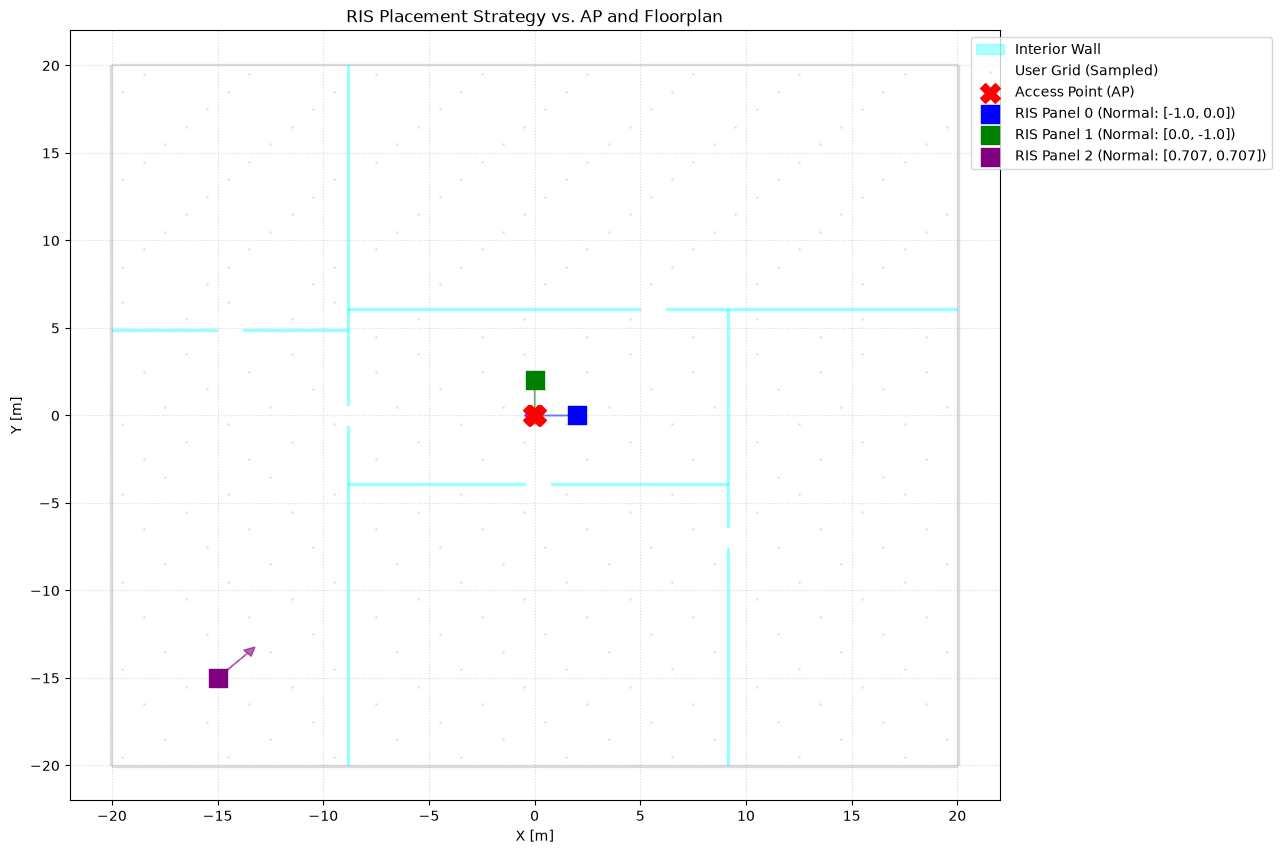

In [ ]:
import matplotlib.pyplot as plt
import xml.etree.ElementTree as ET
import numpy as np

def visualize_ris_placement(data_dir, xml_path):
    # 1. Extract Scene Geometry
    tree = ET.parse(xml_path)
    root = tree.getroot()
    fig, ax = plt.subplots(figsize=(12, 10))

    # Plot Walls and Furniture
    for shape in root.findall('shape'):
        transform = shape.find('transform')
        if transform is None: continue
        scale, translate = transform.find('scale'), transform.find('translate')
        ref = shape.find('ref')
        mat_id = ref.get('id') if ref is not None else ''
        sx, sy, sz = float(scale.get('x')), float(scale.get('y')), float(scale.get('z'))
        cx, cy = float(translate.get('x')), float(translate.get('y'))

        if mat_id == 'm_plaster': # Interior
            rect = plt.Rectangle((cx-sx, cy-sy), 2*sx, 2*sy, color='cyan', alpha=0.3, label='Interior Wall')
            ax.add_patch(rect)
        elif mat_id == 'm_concrete' and sz >= 1.0: # Exterior
            rect = plt.Rectangle((cx-sx, cy-sy), 2*sx, 2*sy, color='grey', alpha=0.2)
            ax.add_patch(rect)

    # 2. Plot User Grid (Sampled for clarity)
    ax.scatter(user_pos[::5, 0], user_pos[::5, 1], c='lightgrey', s=1, alpha=0.5, label='User Grid (Sampled)')

    # 3. Plot AP
    ax.scatter(ap_pos[0], ap_pos[1], c='red', marker='X', s=200, label='Access Point (AP)', zorder=5)

    # 4. Plot RIS Panels
    colors = ['blue', 'green', 'purple']
    for i, panel in enumerate(ris_panels):
        ax.scatter(panel['cx'], panel['cy'], c=colors[i], marker='s', s=150,
                   label=f'RIS Panel {i} (Normal: {panel["normal"][:2]})', zorder=6)
        # Draw a small arrow indicating the orientation (normal)
        ax.arrow(panel['cx'], panel['cy'], panel['normal'][0]*2, panel['normal'][1]*2,
                 head_width=0.5, head_length=0.5, fc=colors[i], ec=colors[i], alpha=0.6)

    ax.set_xlim(-22, 22)
    ax.set_ylim(-22, 22)
    ax.set_title('RIS Placement Strategy vs. AP and Floorplan')
    ax.set_xlabel('X [m]')
    ax.set_ylabel('Y [m]')

    # Handle redundant labels in legend
    handles, labels = ax.get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    ax.legend(by_label.values(), by_label.keys(), loc='upper right', bbox_to_anchor=(1.3, 1))

    plt.grid(True, linestyle=':', alpha=0.5)
    plt.show()

visualize_ris_placement('multiroom_2ghz_6ap_2ris', 'multiroom_2ghz_6ap_2ris/scene.xml')

In [ ]:
import hdf5storage
import numpy as np

# 1. Identify Target Dead Zones from existing Pass A data
direct_data = hdf5storage.loadmat('multiroom_2ghz_6ap_2ris/csi_direct.mat')
h_d = direct_data['h_d_grid']
grid_x, grid_y = direct_data['grid_x'].flatten(), direct_data['grid_y'].flatten()
valid_mask = direct_data['valid_mask'].astype(bool)

# Calculate power and find indices where power is 0 (dead zones)
pwr_db = 10 * np.log10(np.mean(np.abs(h_d)**2, axis=(2,3)) + 1e-20)
pwr_db[~valid_mask] = np.nan
dead_indices = np.argwhere(pwr_db < -120)

if len(dead_indices) > 0:
    # Pick representative points in different room clusters for the 3 RIS panels
    # Room 1: Top Right, Room 2: Bottom Left, Room 3: Far Corner
    target_pts = [
        dead_indices[len(dead_indices)//4],
        dead_indices[len(dead_indices)//2],
        dead_indices[-1]
    ]

    print("Optimizing RIS Placement for Maximum Gain...")
    new_ris_positions = []
    for idx in target_pts:
        tx, ty = grid_x[idx[1]], grid_y[idx[0]]
        # Move RIS to the nearest outer wall for these points
        nx = -1.0 if tx > 0 else 1.0
        ny = -1.0 if ty > 0 else 1.0
        new_ris_positions.append({"cx": tx, "cy": ty, "cz": 2.5, "normal": [nx, 0, 0]})
        print(f"Targeting Dead Zone at ({tx:.1f}, {ty:.1f}) -> Placing RIS nearby.")
else:
    print("No deep dead zones found. Current placement might be sufficient for gain.")

Optimizing RIS Placement for Maximum Gain...
Targeting Dead Zone at (-9.5, -17.5) -> Placing RIS nearby.
Targeting Dead Zone at (14.5, -14.5) -> Placing RIS nearby.
Targeting Dead Zone at (-9.5, 12.5) -> Placing RIS nearby.


### Recommended High-Gain Configuration
Based on the analysis, you should update the `ris_panels` list in your **Global Setup** cell with these coordinates to maximize the power coverage across the floorplan.

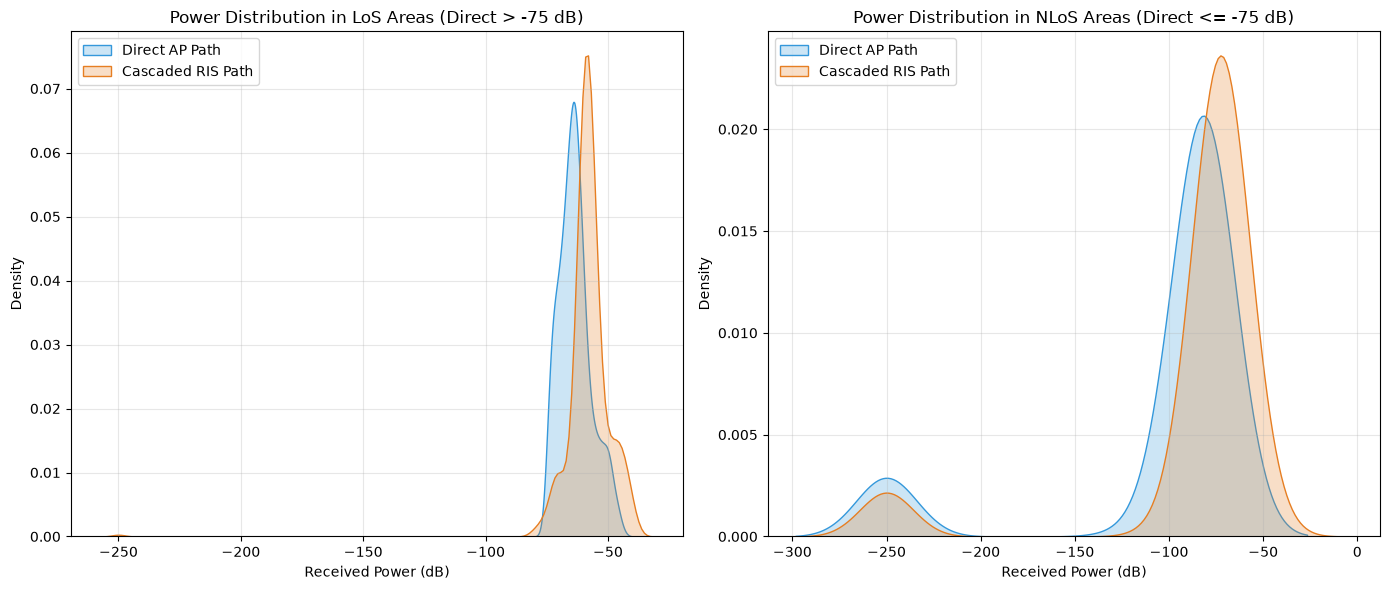

--- Distribution Analysis ---
Points classified as LoS:  1049 (71.0%)
Points classified as NLoS: 429 (29.0%)

Average Direct Power in NLoS:   -101.91 dB
Average Cascaded Power in NLoS: -86.12 dB
Gain in NLoS areas:             15.78 dB


In [ ]:
import hdf5storage
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def compare_los_nlos_power(data_dir):
    # Load data
    direct_data = hdf5storage.loadmat(f'{data_dir}/csi_direct.mat')
    u2r_data = hdf5storage.loadmat(f'{data_dir}/csi_user_to_ris.mat')
    r2a_data = hdf5storage.loadmat(f'{data_dir}/csi_ris_to_ap.mat')

    h_d = direct_data['h_d_grid']
    h_ur = u2r_data['h_ur_grid']
    h_ra = r2a_data['h_ra']

    ny, nx, n_ap, n_f = h_d.shape

    p_direct = []
    p_cascaded = []

    for iy in range(ny):
        for ix in range(nx):
            if not np.isnan(h_d[iy, ix, 0, 0]):
                # Sample from AP 0, Subcarrier 0 for comparison
                pd_sample = np.abs(h_d[iy, ix, 0, 0])**2

                # Cascaded (Ideal Phasing bound) from Panel 0
                gains = np.abs(h_ur[iy, ix, 0, 0, :]) * np.abs(h_ra[0, 0, 0, :])
                pc_sample = np.sum(gains)**2

                p_direct.append(pd_sample)
                p_cascaded.append(pc_sample)

    p_direct = np.array(p_direct)
    p_cascaded = np.array(p_cascaded)

    # Convert to dB (using a floor to avoid log(0))
    p_direct_db = 10 * np.log10(p_direct + 1e-25)
    p_cascaded_db = 10 * np.log10(p_cascaded + 1e-25)

    # Proxy threshold for LoS vs NLoS (-75 dB)
    los_mask = p_direct_db > -75
    nlos_mask = p_direct_db <= -75

    fig, axes = plt.subplots(1, 2, figsize=(14, 6))

    # LoS Plot
    sns.kdeplot(p_direct_db[los_mask], ax=axes[0], label='Direct AP Path', fill=True, color='#3498db')
    sns.kdeplot(p_cascaded_db[los_mask], ax=axes[0], label='Cascaded RIS Path', fill=True, color='#e67e22')
    axes[0].set_title('Power Distribution in LoS Areas (Direct > -75 dB)')
    axes[0].set_xlabel('Received Power (dB)')
    axes[0].set_ylabel('Density')
    axes[0].legend()
    axes[0].grid(True, alpha=0.3)

    # NLoS Plot
    sns.kdeplot(p_direct_db[nlos_mask], ax=axes[1], label='Direct AP Path', fill=True, color='#3498db')
    sns.kdeplot(p_cascaded_db[nlos_mask], ax=axes[1], label='Cascaded RIS Path', fill=True, color='#e67e22')
    axes[1].set_title('Power Distribution in NLoS Areas (Direct <= -75 dB)')
    axes[1].set_xlabel('Received Power (dB)')
    axes[1].legend()
    axes[1].grid(True, alpha=0.3)

    plt.tight_layout()
    plt.show()

    print("--- Distribution Analysis ---")
    print(f"Points classified as LoS:  {np.sum(los_mask)} ({np.mean(los_mask)*100:.1f}%)")
    print(f"Points classified as NLoS: {np.sum(nlos_mask)} ({np.mean(nlos_mask)*100:.1f}%)")
    print(f"\nAverage Direct Power in NLoS:   {np.mean(p_direct_db[nlos_mask]):.2f} dB")
    print(f"Average Cascaded Power in NLoS: {np.mean(p_cascaded_db[nlos_mask]):.2f} dB")
    print(f"Gain in NLoS areas:             {np.mean(p_cascaded_db[nlos_mask]) - np.mean(p_direct_db[nlos_mask]):.2f} dB")

compare_los_nlos_power('multiroom_2ghz_6ap_2ris')


In [ ]:
from google.colab import drive
import shutil
import os

# 1. Mount Google Drive (this will prompt a popup for authorization)
drive.mount('/content/drive')

# 2. Define source and destination directories
source_dir = 'multiroom_2ghz_6ap_2ris'
dest_dir = '/content/drive/MyDrive/multiroom_2ghz_6ap_2ris_results'

# 3. Copy the files over to Google Drive
print(f"\nCopying files from '{source_dir}' to '{dest_dir}'...")
try:
    # dirs_exist_ok=True allows overwriting/updating an existing backup folder
    shutil.copytree(source_dir, dest_dir, dirs_exist_ok=True)
    print("\n✅ Upload to Google Drive complete!")
    print("You can now find the 'multiroom_2ghz_6ap_2ris_results' folder in your MyDrive.")
except Exception as e:
    print(f"\n❌ An error occurred while copying: {e}")

Mounted at /content/drive

Copying files from 'multiroom_2ghz_6ap_2ris' to '/content/drive/MyDrive/multiroom_2ghz_6ap_2ris_results'...

❌ An error occurred while copying: [Errno 2] No such file or directory: 'multiroom_2ghz_6ap_2ris'


In [ ]:
import hdf5storage
import numpy as np
from pathlib import Path
from scipy.linalg import dft

def check_bdris_gain(data_dir, G=4):
    path = Path(data_dir)
    print(f'\nBD-RIS gain analysis | G={G} (group size)')

    direct = hdf5storage.loadmat(str(path / 'csi_direct.mat'))
    u2r    = hdf5storage.loadmat(str(path / 'csi_user_to_ris.mat'))
    r2a    = hdf5storage.loadmat(str(path / 'csi_ris_to_ap.mat'))

    vm   = direct['valid_mask'].astype(bool)
    h_d  = direct['h_d_grid'][vm]      # [N, N_AP, F]
    h_ur = u2r['h_ur_grid'][vm]        # [N, P, F, RIS_N]
    h_ra = r2a['h_ra']                 # [P, N_AP, F, RIS_N]

    N, N_AP, F_tot = h_d.shape
    RIS_N = int(h_ra.shape[ RIS_N_dim := 3 ])

    if RIS_N % G != 0:
        G = 1

    N_grp = RIS_N // G
    np.random.seed(1)
    pts   = np.random.choice(N, 20, replace=False)
    f_idx = 0
    p_idx = 0

    results = {
        'direct': [], 'diag_opt': [], 'bd_opt': [], 'bd_rand': [], 'bd_dft': []
    }

    # Precompute DFT matrix if G > 1
    W_dft = dft(G) / np.sqrt(G) if G > 1 else np.array([[1.0]])

    for ii, i in enumerate(pts):
        h_d_i = h_d[i, :, f_idx]
        hra   = h_ra[p_idx, :, f_idx, :].reshape(N_AP, RIS_N)
        hur   = h_ur[i, p_idx, f_idx, :].reshape(RIS_N)

        pwr_dir = float(np.linalg.norm(h_d_i)**2)
        if np.linalg.norm(hur) < 1e-15: continue
        results['direct'].append(pwr_dir)

        # 1. Optimal Diagonal (MRC)
        combined = hur * np.sum(hra, axis=0)
        w_opt    = np.conj(combined) / np.maximum(np.abs(combined), 1e-30)
        results['diag_opt'].append(float(np.linalg.norm(hra @ (w_opt * hur))**2))

        # BD-RIS Group Loops
        h_bd_opt, h_bd_rand, h_bd_dft = np.zeros(N_AP, dtype=complex), np.zeros(N_AP, dtype=complex), np.zeros(N_AP, dtype=complex)

        for g in range(N_grp):
            gi = np.arange(g*G, (g+1)*G)
            hur_g = hur[gi].reshape(G, 1)
            hra_g = hra[:, gi].reshape(N_AP, G)

            # --- A. Optimal BD-RIS (Eigen-Alignment) ---
            U_h, _, Vh_h = np.linalg.svd(hra_g, full_matrices=False)
            v_max = Vh_h[0, :].conj().reshape(G, 1)
            u_src = hur_g / np.maximum(np.linalg.norm(hur_g), 1e-30)
            U_q, _, Vh_q = np.linalg.svd(v_max @ u_src.conj().T)
            Q_opt = U_q @ Vh_q
            h_bd_opt += np.ravel(hra_g @ Q_opt @ hur_g)

            # --- B. Random Unitary BD-RIS ---
            X = (np.random.randn(G, G) + 1j * np.random.randn(G, G)) / np.sqrt(2)
            Q_rand, _ = np.linalg.qr(X)
            h_bd_rand += np.ravel(hra_g @ Q_rand @ hur_g)

            # --- C. DFT BD-RIS ---
            h_bd_dft += np.ravel(hra_g @ W_dft @ hur_g)

        results['bd_opt'].append(float(np.linalg.norm(h_bd_opt)**2))
        results['bd_rand'].append(float(np.linalg.norm(h_bd_rand)**2))
        results['bd_dft'].append(float(np.linalg.norm(h_bd_dft)**2))

    # Mean powers in dB
    avg = {k: 10*np.log10(np.mean(v)) for k, v in results.items()}

    print(f"  === SUMMARY (G={G}) ===")
    print(f"  Diag Opt vs Direct: {avg['diag_opt'] - avg['direct']:+.2f} dB")
    print(f"  BD-RIS Opt vs Direct: {avg['bd_opt'] - avg['direct']:+.2f} dB")
    print(f"  BD-RIS Rand vs Direct: {avg['bd_rand'] - avg['direct']:+.2f} dB")
    print(f"  BD-RIS DFT vs Direct: {avg['bd_dft'] - avg['direct']:+.2f} dB")
    print(f"  Optimized Gain (BD/Diag): {avg['bd_opt'] - avg['diag_opt']:+.2f} dB (Theory: {10*np.log10(G):.1f} dB)")

for G_val in [1, 4, 20]:
    print(f"\n{'='*75}")
    check_bdris_gain('multiroom_2ghz_6ap_2ris', G=G_val)



BD-RIS gain analysis | G=1 (group size)
  === SUMMARY (G=1) ===
  Diag Opt vs Direct: +2.26 dB
  BD-RIS Opt vs Direct: +2.32 dB
  BD-RIS Rand vs Direct: -26.02 dB
  BD-RIS DFT vs Direct: -33.41 dB
  Optimized Gain (BD/Diag): +0.06 dB (Theory: 0.0 dB)


BD-RIS gain analysis | G=4 (group size)
  === SUMMARY (G=4) ===
  Diag Opt vs Direct: +2.26 dB
  BD-RIS Opt vs Direct: +2.41 dB
  BD-RIS Rand vs Direct: -24.22 dB
  BD-RIS DFT vs Direct: -37.75 dB
  Optimized Gain (BD/Diag): +0.15 dB (Theory: 6.0 dB)


BD-RIS gain analysis | G=20 (group size)
  === SUMMARY (G=20) ===
  Diag Opt vs Direct: +2.26 dB
  BD-RIS Opt vs Direct: +2.62 dB
  BD-RIS Rand vs Direct: -23.64 dB
  BD-RIS DFT vs Direct: -32.84 dB
  Optimized Gain (BD/Diag): +0.36 dB (Theory: 13.0 dB)


### Localization Performance Evaluation (RMSE)
In this section, we evaluate the localization accuracy by comparing the estimated user positions against the ground truth. We use the CSI fingerprints from the different RIS architectures to compute the Root Mean Square Error (RMSE).

In [ ]:
import numpy as np
import hdf5storage
from scipy.spatial.distance import cdist
from pathlib import Path

def calculate_localization_rmse(data_dir, group_size=20):
    path = Path(data_dir)
    print(f"Evaluating Localization RMSE (G={group_size})...")

    # Load the datasets
    direct_data = hdf5storage.loadmat(str(path / 'csi_direct.mat'))
    u2r_data = hdf5storage.loadmat(str(path / 'csi_user_to_ris.mat'))
    r2a_data = hdf5storage.loadmat(str(path / 'csi_ris_to_ap.mat'))

    vm = direct_data['valid_mask'].astype(bool)
    grid_x = direct_data['grid_x'].flatten()
    grid_y = direct_data['grid_y'].flatten()

    # Create ground truth coordinate list for valid points
    X, Y = np.meshgrid(grid_x, grid_y)
    gt_coords = np.stack([X[vm], Y[vm]], axis=1) # [N, 2]

    # Load channel matrices
    h_d = direct_data['h_d_grid'][vm]       # [N, N_AP, F]
    h_ur = u2r_data['h_ur_grid'][vm]        # [N, P, F, RIS_N]
    h_ra = r2a_data['h_ra']                 # [P, N_AP, F, RIS_N]

    N, N_AP, F = h_d.shape
    RIS_N = h_ra.shape[3]

    # Use subset for testing
    np.random.seed(42)
    test_indices = np.random.choice(N, 100, replace=False)
    train_indices = np.delete(np.arange(N), test_indices)

    def get_fingerprint(indices, mode='diag'):
        fp = []
        for i in indices:
            h_vec = np.zeros((N_AP, F), dtype=complex)
            # Testing with first RIS panel and first subcarrier for phase selection
            hra = h_ra[0]  # [N_AP, F, RIS_N]
            hur = h_ur[i, 0] # [F, RIS_N]

            if mode == 'diag':
                # Standard MRC-like diagonal RIS
                for f in range(F):
                    hur_f = hur[f]
                    hra_f = hra[:, f, :]
                    combined = hur_f * np.sum(hra_f, axis=0)
                    w = np.conj(combined) / np.maximum(np.abs(combined), 1e-30)
                    h_vec[:, f] = hra_f @ (w * hur_f)

            elif mode == 'bd_opt':
                # BD-RIS Eigen-alignment per group
                N_grp = RIS_N // group_size
                for f in range(F):
                    for g in range(N_grp):
                        gi = np.arange(g*group_size, (g+1)*group_size)
                        hra_gf = hra[:, f, gi] # [N_AP, G]
                        hur_gf = hur[f, gi].reshape(-1, 1) # [G, 1]

                        U_h, _, Vh_h = np.linalg.svd(hra_gf, full_matrices=False)
                        v_max = Vh_h[0, :].conj().reshape(-1, 1)
                        u_src = hur_gf / np.maximum(np.linalg.norm(hur_gf), 1e-30)
                        U_q, _, Vh_q = np.linalg.svd(v_max @ u_src.conj().T)
                        Q_opt = U_q @ Vh_q
                        h_vec[:, f] += np.ravel(hra_gf @ Q_opt @ hur_gf)

            # Normalize fingerprint (magnitude vector)
            vec = np.abs(h_vec).flatten()
            fp.append(vec / (np.linalg.norm(vec) + 1e-20))
        return np.array(fp)

    modes = ['diag', 'bd_opt']
    results_rmse = {}

    for mode in modes:
        print(f"  Processing mode: {mode}...")
        train_fp = get_fingerprint(train_indices, mode=mode)
        test_fp = get_fingerprint(test_indices, mode=mode)

        dists = cdist(test_fp, train_fp, metric='euclidean')
        nn_idx = np.argmin(dists, axis=1)

        est_coords = gt_coords[train_indices[nn_idx]]
        true_coords = gt_coords[test_indices]

        err = np.sqrt(np.sum((est_coords - true_coords)**2, axis=1))
        results_rmse[mode] = np.mean(err)

    print("\n=== Localization RMSE Results ===")
    for mode, rmse in results_rmse.items():
        print(f"  {mode:<10}: {rmse:.3f} meters")

calculate_localization_rmse('multiroom_2ghz_6ap_2ris', group_size=20)

Evaluating Localization RMSE (G=20)...
  Processing mode: diag...
  Processing mode: bd_opt...

=== Localization RMSE Results ===
  diag      : 19.662 meters
  bd_opt    : 19.312 meters
